# Exploring ACCRE GOF jumps across abstraction orders (`real_xmin2`)

This notebook investigates why ACCRE’s Clauset GOF $p$-values change substantially between behavioral n-gram orders, focusing on **$k=4$ versus $k=5$ with fixed `xmin=2`**.

It reuses repository loaders, frequency extraction, discrete power-law fitting, and CDF conventions. It does **not** rerun the full Slurm experiment. Extra bootstrap sampling is gated and off by default.


## 1. Configuration and data loading

In [137]:
from __future__ import annotations

import math
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import powerlaw
from IPython.display import display
from scipy.stats import wasserstein_distance

# Resolve repo root even when the kernel cwd is analyses/powerlaw_statistics/.
def _find_repo_root() -> Path:
    here = Path.cwd().resolve()
    candidates = [here, *here.parents]
    # Notebook file location (Cursor / Jupyter often keep cwd elsewhere).
    nb_file = Path("explore_gof_jumps.ipynb").resolve()
    if nb_file.is_file():
        candidates = [nb_file.parent, *nb_file.parent.parents, *candidates]
    for candidate in candidates:
        if (candidate / "utils" / "powerlaw").is_dir() and (candidate / "results").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate repo root (expected utils/powerlaw and results/)."
    )

REPO_ROOT = _find_repo_root()
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from utils.constants import ATTACHMENTS_DIR, DATA_DICTIONARY_PATH, POWERLAW_STATISTICS_DIR
from utils.io import get_data_dictionary, get_event_log_from_dictionary, load_attachments
from utils.io.attachments import START, END, _extended_trace, _ngram_nodes, extract_attachments_from_trace_data, trace_completion_data
from utils.powerlaw.analyze import (
    LOWER_BOUNDED_POWER_LAW,
    _GOF_KIND_REFIT,
    _powerlaw_fit_with_stats,
    bootstrap_gof,
)
from utils.rfc import extract_frequency_counts

# Absolute paths so relative constants stay valid after chdir.
ATTACHMENTS_ROOT = (REPO_ROOT / ATTACHMENTS_DIR).resolve()
DATA_DICTIONARY = (REPO_ROOT / DATA_DICTIONARY_PATH).resolve()

# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
EXPERIMENT_ID = "real_xmin2"
LOG_NAME = "ACCRE"
K_BEFORE = 4
K_AFTER = 5
FIXED_XMIN = 2
MODEL = LOWER_BOUNDED_POWER_LAW
RUN_ADDITIONAL_BOOTSTRAPS = False
OPTIONAL_BOOTSTRAP_REPS = 250  # only if RUN_ADDITIONAL_BOOTSTRAPS
OPTIONAL_BOOTSTRAP_SEED = 42

RESULTS_ROOT = (REPO_ROOT / POWERLAW_STATISTICS_DIR / EXPERIMENT_ID).resolve()
SUMMARY_ALL = RESULTS_ROOT / "summary_all_concepts.csv"
FIG_DIR = RESULTS_ROOT / "explore_gof_jumps"
FIG_DIR.mkdir(parents=True, exist_ok=True)

assert RESULTS_ROOT.is_dir(), f"Missing results root: {RESULTS_ROOT}"
assert SUMMARY_ALL.is_file(), f"Missing summary: {SUMMARY_ALL}"

print(f"REPO_ROOT={REPO_ROOT}")
print(f"cwd={Path.cwd()}")
print(f"RESULTS_ROOT={RESULTS_ROOT}")
print(f"ATTACHMENTS_ROOT={ATTACHMENTS_ROOT}")
print(f"FIG_DIR={FIG_DIR}")
print(f"RUN_ADDITIONAL_BOOTSTRAPS={RUN_ADDITIONAL_BOOTSTRAPS}")


REPO_ROOT=/vol/tmp/eberlenn/process-mining-rfcs
cwd=/vol/tmp/eberlenn/process-mining-rfcs
RESULTS_ROOT=/vol/tmp/eberlenn/process-mining-rfcs/results/powerlaw_statistics/real_xmin2
ATTACHMENTS_ROOT=/vol/tmp/eberlenn/process-mining-rfcs/results/attachments
FIG_DIR=/vol/tmp/eberlenn/process-mining-rfcs/results/powerlaw_statistics/real_xmin2/explore_gof_jumps
RUN_ADDITIONAL_BOOTSTRAPS=False


In [138]:
def concept_sort_key(concept: str):
    """Sort n-gram concepts numerically; put non-n* (e.g. variants) at the end."""
    if isinstance(concept, str) and concept.startswith("n") and concept[1:].isdigit():
        return (0, int(concept[1:]))
    return (1, str(concept))


def k_from_concept(concept: str) -> int | None:
    if isinstance(concept, str) and concept.startswith("n") and concept[1:].isdigit():
        return int(concept[1:])
    return None


def attachment_path(concept: str, log_name: str = LOG_NAME) -> Path:
    return ATTACHMENTS_ROOT / concept / log_name / "attachments.csv.gz"


def load_summary_accre(path: Path = SUMMARY_ALL) -> pd.DataFrame:
    df = pd.read_csv(path)
    df = df[df["log_name"] == LOG_NAME].copy()
    df["concept"] = df["concept"].astype(str)
    df = df.sort_values("concept", key=lambda s: s.map(concept_sort_key)).reset_index(drop=True)
    return df


summary = load_summary_accre()
print(f"Loaded {len(summary)} ACCRE rows from {SUMMARY_ALL}")
print("Concepts:", list(summary["concept"]))
display(summary[["concept", "xmin", "gof_p", "KS_D", "n_fitted_types", "alpha"]].head(10))


Loaded 23 ACCRE rows from /vol/tmp/eberlenn/process-mining-rfcs/results/powerlaw_statistics/real_xmin2/summary_all_concepts.csv
Concepts: ['n1', 'n2', 'n3', 'n4', 'n5', 'n6', 'n7', 'n8', 'n9', 'n10', 'n11', 'n12', 'n13', 'n14', 'n15', 'n16', 'n17', 'n18', 'n19', 'n20', 'variants', 'variants', 'variants']


,concept,xmin,gof_p,KS_D,n_fitted_types,alpha
0,n1,2.0,0.0096,0.302784,16,1.276981
1,n2,2.0,0.0244,0.122218,70,1.545553
2,n3,2.0,0.0116,0.110518,94,1.698352
3,n4,2.0,0.0204,0.100114,101,1.776979
4,n5,2.0,0.5176,0.051265,90,1.845306
5,n6,2.0,0.5140,0.057933,69,1.869356
6,n7,2.0,0.7312,0.053729,53,1.857321
7,n8,2.0,0.5156,0.069856,45,1.895529
8,n9,2.0,0.9280,0.043555,38,1.905557
9,n10,2.0,0.9848,0.034937,34,1.911530


### ACCRE trace-length distribution

Each case contributes once (activity-sequence length). The box plot marks the median (box center line) and mean; the step curve is the empirical CDF of those lengths as a percentage of traces.


ACCRE: n=398 traces | mean=4.887, median=4.000, Q1=4.000, Q3=6.000, min=1, max=21


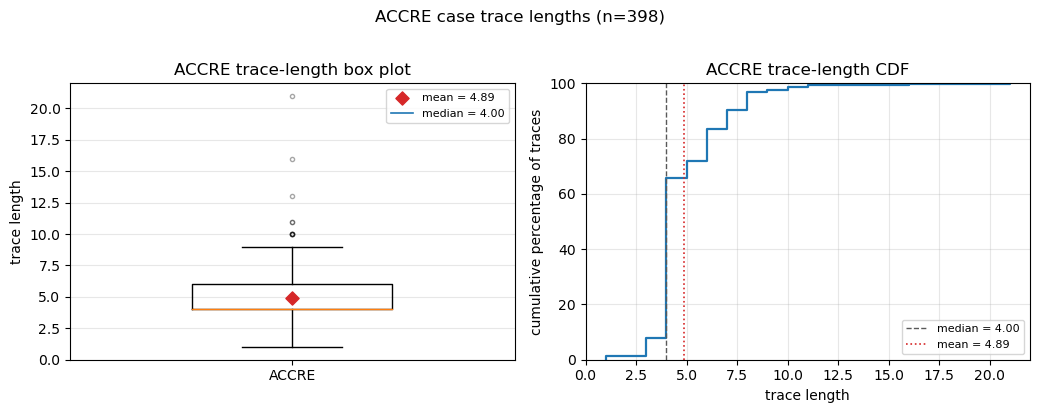

Wrote /vol/tmp/eberlenn/process-mining-rfcs/results/powerlaw_statistics/real_xmin2/explore_gof_jumps/accre_trace_length_distribution.png


In [139]:
# Load ACCRE once for length diagnostics (reused in section 6 if already present).
from collections import Counter

if "trace_rows" not in globals():
    data_dictionary = get_data_dictionary(DATA_DICTIONARY, get_real=True, get_synthetic=False)
    event_log = get_event_log_from_dictionary(LOG_NAME, data_dictionary)
    trace_rows = trace_completion_data(event_log)

case_lengths = np.asarray(
    [len(row["activity_sequence"]) for row in trace_rows],
    dtype=float,
)
n_traces = int(case_lengths.size)
len_mean = float(np.mean(case_lengths))
len_median = float(np.median(case_lengths))
len_q1, len_q3 = np.quantile(case_lengths, [0.25, 0.75])
print(
    f"{LOG_NAME}: n={n_traces} traces | "
    f"mean={len_mean:.3f}, median={len_median:.3f}, "
    f"Q1={len_q1:.3f}, Q3={len_q3:.3f}, "
    f"min={case_lengths.min():.0f}, max={case_lengths.max():.0f}"
)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0))

# --- Box plot ---
ax = axes[0]
ax.boxplot(
    case_lengths,
    vert=True,
    widths=0.45,
    showfliers=True,
    flierprops={"marker": "o", "markersize": 3, "alpha": 0.35},
)
ax.scatter(
    [1],
    [len_mean],
    marker="D",
    s=45,
    color="tab:red",
    zorder=3,
    label=f"mean = {len_mean:.2f}",
)
ax.plot([], [], color="C0", lw=1.2, label=f"median = {len_median:.2f}")
ax.set_xticks([1])
ax.set_xticklabels([LOG_NAME])
ax.set_ylabel("trace length")
ax.set_title(f"{LOG_NAME} trace-length box plot")
ax.grid(True, axis="y", alpha=0.3)
ax.legend(loc="upper right", fontsize=8)

# --- Cumulative percentage ---
ax = axes[1]
lengths_sorted = np.sort(case_lengths)
cdf_pct = 100.0 * np.arange(1, n_traces + 1) / n_traces
ax.step(lengths_sorted, cdf_pct, where="post", color="tab:blue", lw=1.6)
ax.axvline(len_median, color="0.35", ls="--", lw=1.0, label=f"median = {len_median:.2f}")
ax.axvline(len_mean, color="tab:red", ls=":", lw=1.2, label=f"mean = {len_mean:.2f}")
ax.set_xlabel("trace length")
ax.set_ylabel("cumulative percentage of traces")
ax.set_ylim(0, 100)
ax.set_title(f"{LOG_NAME} trace-length CDF")
ax.grid(True, alpha=0.3)
ax.legend(loc="lower right", fontsize=8)

fig.suptitle(f"{LOG_NAME} case trace lengths (n={n_traces})", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "accre_trace_length_distribution.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "accre_trace_length_distribution.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"Wrote {FIG_DIR / 'accre_trace_length_distribution.png'}")


## 2. Overview of existing results

,log,concept,n_occurrences,n_types,n_fitted_types,xmin,alpha,best_other_distribution,KS_D,n_failed,gof_kind,gof_p
0,ACCRE,n1,"1,945",16,16,2,1.2770,stretched_exponential,0.3028,0.000000,refit_all_parameters,0.96%
1,ACCRE,n2,"2,343",98,70,2,1.5456,stretched_exponential,0.1222,0.000000,refit_all_parameters,2.44%
2,ACCRE,n3,"1,945",156,94,2,1.6984,stretched_exponential,0.1105,0.000000,refit_all_parameters,1.16%
3,ACCRE,n4,"1,553",184,101,2,1.7770,stretched_exponential,0.1001,0.000000,refit_all_parameters,2.04%
4,ACCRE,n5,"1,161",195,90,2,1.8453,stretched_exponential,0.0513,0.000000,refit_all_parameters,51.76%
5,ACCRE,n6,795,183,69,2,1.8694,stretched_exponential,0.0579,0.000000,refit_all_parameters,51.40%
6,ACCRE,n7,659,163,53,2,1.8573,stretched_exponential,0.0537,0.000000,refit_all_parameters,73.12%
7,ACCRE,n8,547,140,45,2,1.8955,stretched_exponential,0.0699,0.000000,refit_all_parameters,51.56%
8,ACCRE,n9,481,117,38,2,1.9056,stretched_exponential,0.0436,0.000000,refit_all_parameters,92.80%
9,ACCRE,n10,443,105,34,2,1.9115,lognormal,0.0349,0.000000,refit_all_parameters,98.48%


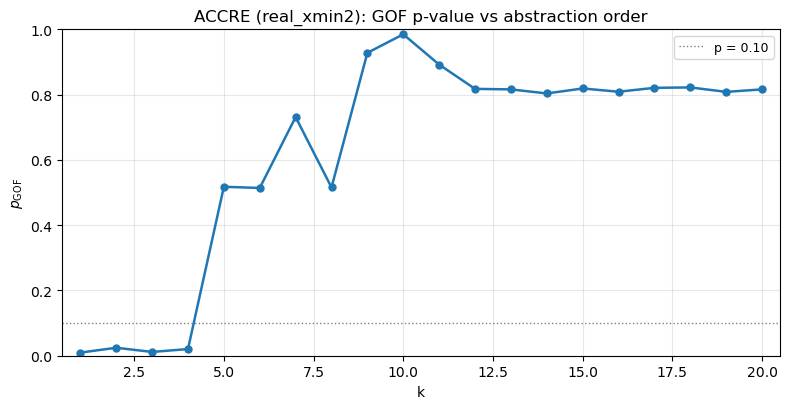

Wrote /vol/tmp/eberlenn/process-mining-rfcs/results/powerlaw_statistics/real_xmin2/explore_gof_jumps/overview_accre_real_xmin2.csv


In [140]:
# Column mapping: repository names -> display names used below.
# log_name -> log; concept unchanged; remaining names match the request.

overview_cols = [
    "log_name",
    "concept",
    "n_occurrences",
    "n_types",
    "n_fitted_types",
    "xmin",
    "alpha",
    "gof_p",
    "best_other_distribution",
    "KS_D",
    "n_failed",
    "gof_kind",
]
overview = summary[overview_cols].rename(columns={"log_name": "log"}).copy()

# Display gof_p as percent while keeping numeric gof_p for styling.
overview_disp = overview.copy()
overview_disp["gof_p_pct"] = overview_disp["gof_p"].map(
    lambda p: "NA" if pd.isna(p) else f"{100.0 * float(p):.2f}%"
)

def _gof_color(p: float) -> str:
    """Red (0) -> yellow (~0.5) -> green (1) for gof_p in [0, 1]."""
    if pd.isna(p):
        return ""
    p = float(np.clip(p, 0.0, 1.0))
    # interpolate red->green in RGB
    r = int(round(255 * (1 - p)))
    g = int(round(255 * p))
    b = 40
    return f"background-color: rgb({r},{g},{b}); color: {'white' if p < 0.25 or p > 0.75 else 'black'}"

styled = (
    overview_disp.drop(columns=["gof_p"])
    .rename(columns={"gof_p_pct": "gof_p"})
    .style.apply(
        lambda col: [
            _gof_color(overview.loc[i, "gof_p"]) if col.name == "gof_p" else ""
            for i in overview.index
        ],
        axis=0,
    )
    .format(
        {
            "alpha": "{:.4f}",
            "KS_D": "{:.4f}",
            "xmin": "{:.0f}",
            "n_occurrences": "{:,.0f}",
            "n_types": "{:,.0f}",
            "n_fitted_types": "{:,.0f}",
        },
        na_rep="NA",
    )
)
display(styled)

# Line plot: GOF p vs abstraction order k
plot_df = overview.copy()
plot_df["k"] = plot_df["concept"].map(
    lambda c: int(c[1:]) if isinstance(c, str) and c.startswith("n") and c[1:].isdigit() else pd.NA
)
plot_df = plot_df.dropna(subset=["k", "gof_p"]).sort_values("k")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(plot_df["k"], plot_df["gof_p"], "o-", color="tab:blue", lw=1.8, ms=5)
ax.axhline(0.10, color="gray", ls=":", lw=1, label="p = 0.10")
ax.set_xlabel("k")
ax.set_ylabel(r"$p_{\mathrm{GOF}}$")
ax.set_ylim(0.0, 1.0)
ax.set_xlim(left=float(plot_df["k"].min()) - 0.5, right=float(plot_df["k"].max()) + 0.5)
ax.set_title(f"{LOG_NAME} ({EXPERIMENT_ID}): GOF p-value vs abstraction order")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "gof_p_vs_k.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "gof_p_vs_k.png", dpi=160, bbox_inches="tight")
plt.show()

overview.to_csv(FIG_DIR / "overview_accre_real_xmin2.csv", index=False)
print(f"Wrote {FIG_DIR / 'overview_accre_real_xmin2.csv'}")


### Note on the $k=4 \to k=5$ jump

For ACCRE with fixed `xmin=2`, $p_{\mathrm{GOF}}$ increases from approximately **2.04%** at $k=4$ to **51.76%** at $k=5$. The observed KS distance decreases from approximately **0.1001** to **0.0513**, while fitted-type count decreases from **101** to **90**. We investigate where the distribution changes and which properties of the abstraction may contribute.

## 3. Recover and validate the frequency data

In [141]:
def load_frequencies(concept: str) -> np.ndarray:
    """Frequency multiset: one observation per distinct behavioral type (occurrence count)."""
    path = attachment_path(concept)
    if not path.is_file():
        raise FileNotFoundError(path)
    return extract_frequency_counts(load_attachments(path))


def descriptive_from_freqs(freqs: np.ndarray, xmin: float) -> dict:
    freqs = np.asarray(freqs, dtype=int)
    fitted = freqs[freqs >= xmin]
    return {
        "n_occurrences": int(freqs.sum()),
        "n_types": int(freqs.size),
        "n_singletons": int(np.sum(freqs == 1)),
        "n_fitted_types": int(fitted.size),
    }


validation_rows = []
recovered = {}
for _, row in summary.iterrows():
    concept = str(row["concept"])
    try:
        freqs = load_frequencies(concept)
    except FileNotFoundError as exc:
        validation_rows.append({"concept": concept, "status": f"missing attachments: {exc}"})
        continue
    recovered[concept] = freqs
    xmin = float(row["xmin"]) if pd.notna(row["xmin"]) else float("nan")
    desc = descriptive_from_freqs(freqs, xmin)
    checks = {
        "n_occurrences": int(row["n_occurrences"]) == desc["n_occurrences"],
        "n_types": int(row["n_types"]) == desc["n_types"],
        "n_singletons": int(row["n_singletons"]) == desc["n_singletons"],
        "n_fitted_types": int(row["n_fitted_types"]) == desc["n_fitted_types"],
    }
    validation_rows.append({
        "concept": concept,
        "status": "ok" if all(checks.values()) else "MISMATCH",
        **{f"ok_{k}": v for k, v in checks.items()},
        **desc,
        "csv_n_occurrences": int(row["n_occurrences"]),
        "csv_n_types": int(row["n_types"]),
        "csv_n_singletons": int(row["n_singletons"]),
        "csv_n_fitted_types": int(row["n_fitted_types"]),
        "xmin": xmin,
    })

validation_df = pd.DataFrame(validation_rows)
display(validation_df)
if (validation_df["status"] != "ok").any():
    print("WARNING: some concepts failed validation")
else:
    print("All available concepts reproduce occurrence / type / singleton / fitted-type counts.")


,concept,status,ok_n_occurrences,ok_n_types,ok_n_singletons,ok_n_fitted_types,n_occurrences,n_types,n_singletons,n_fitted_types,csv_n_occurrences,csv_n_types,csv_n_singletons,csv_n_fitted_types,xmin
0,n1,ok,True,True,True,True,1945,16,0,16,1945,16,0,16,2.0
1,n2,ok,True,True,True,True,2343,98,28,70,2343,98,28,70,2.0
2,n3,ok,True,True,True,True,1945,156,62,94,1945,156,62,94,2.0
3,n4,ok,True,True,True,True,1553,184,83,101,1553,184,83,101,2.0
4,n5,ok,True,True,True,True,1161,195,105,90,1161,195,105,90,2.0
5,n6,ok,True,True,True,True,795,183,114,69,795,183,114,69,2.0
6,n7,ok,True,True,True,True,659,163,110,53,659,163,110,53,2.0
7,n8,ok,True,True,True,True,547,140,95,45,547,140,95,45,2.0
8,n9,ok,True,True,True,True,481,117,79,38,481,117,79,38,2.0
9,n10,ok,True,True,True,True,443,105,71,34,443,105,71,34,2.0


In [142]:
# Reproduce alpha and KS_D for k=4 and k=5 with fixed xmin (same Fit settings as analyze.py).
fit_check_rows = []
fits = {}
for k in (K_BEFORE, K_AFTER):
    concept = f"n{k}"
    freqs = recovered[concept]
    csv_row = summary.loc[summary["concept"] == concept].iloc[0]
    fit_res = _powerlaw_fit_with_stats(freqs, xmin=FIXED_XMIN, xmax=None)
    fits[concept] = fit_res
    alpha_ok = np.isclose(float(fit_res["alpha"]), float(csv_row["alpha"]), rtol=0, atol=1e-10)
    ks_ok = np.isclose(float(fit_res["KS_D"]), float(csv_row["KS_D"]), rtol=0, atol=1e-12)
    fit_check_rows.append({
        "concept": concept,
        "csv_alpha": float(csv_row["alpha"]),
        "repro_alpha": float(fit_res["alpha"]),
        "alpha_match": bool(alpha_ok),
        "csv_KS_D": float(csv_row["KS_D"]),
        "repro_KS_D": float(fit_res["KS_D"]),
        "KS_match": bool(ks_ok),
        "csv_gof_p": float(csv_row["gof_p"]),
        "n_fitted_types": int(fit_res["n_fitted_types"]),
    })

fit_check_df = pd.DataFrame(fit_check_rows)
display(fit_check_df)
if not fit_check_df[["alpha_match", "KS_match"]].to_numpy().all():
    print("WARNING: reproduced alpha/KS disagree with CSV — do not substitute a different convention silently.")
else:
    print("Fixed-xmin discrete Fit reproduces CSV alpha and KS_D for k=4 and k=5.")


,concept,csv_alpha,repro_alpha,alpha_match,csv_KS_D,repro_KS_D,KS_match,csv_gof_p,n_fitted_types
0,n4,1.776979,1.776979,True,0.100114,0.100114,True,0.0204,101
1,n5,1.845306,1.845306,True,0.051265,0.051265,True,0.5176,90


Fixed-xmin discrete Fit reproduces CSV alpha and KS_D for k=4 and k=5.


### Terminology used below

- **Behavioral types**: distinct `node_id` values (n-grams / activities) in the attachments.
- **Occurrences**: attachment rows; total observations $= \sum$ type frequencies.
- **Frequency multiset**: one integer frequency per distinct type (what Clauset fits).
- **Fitted tail**: types with frequency $\ge$ `xmin` (here `xmin=2`).


## 4. Empirical distributions and saved power-law models ($k=4$ vs $k=5$)

No new MLE: empirical curves use the recovered frequency multiset; model curves use **saved** `alpha` / `xmin` from the results table via `powerlaw.Power_Law(..., parameters=[saved_alpha], discrete=True)`.


### A. Empirical and fitted CDFs with linear y-axis

For each order $k=1\ldots10$: `tail_data = frequencies[frequencies >= saved_xmin]`, empirical `powerlaw.plot_cdf(tail_data)`, model `Power_Law(...).plot_cdf(data=x_grid)` with `x_grid = arange(saved_xmin, max(tail_data)+1)`. X log, Y linear on $[0,1]$. Two panels per row; max $|\Delta|$ marked and checked against `KS_D`.

**Convention:** `powerlaw` plots the left-edge tail CDF $P(X < x \mid X \ge x_{\min})$ (so the value at $x=x_{\min}$ is $0$ even if many observations equal $x_{\min}$). The usual right-continuous $P(X \le x \mid X \ge x_{\min})$ would jump at $x_{\min}$ by the point mass there.


CDF k=1: max |Δ|=0.302784 at x=12; KS_D=0.302784; |Δ|-KS_D=0.000e+00 [MATCH]
CDF k=2: max |Δ|=0.122218 at x=3; KS_D=0.122218; |Δ|-KS_D=1.249e-16 [MATCH]
CDF k=3: max |Δ|=0.110518 at x=3; KS_D=0.110518; |Δ|-KS_D=2.776e-17 [MATCH]
CDF k=4: max |Δ|=0.100114 at x=3; KS_D=0.100114; |Δ|-KS_D=-2.776e-17 [MATCH]
CDF k=5: max |Δ|=0.051265 at x=3; KS_D=0.051265; |Δ|-KS_D=0.000e+00 [MATCH]
CDF k=6: max |Δ|=0.057933 at x=3; KS_D=0.057933; |Δ|-KS_D=-9.021e-17 [MATCH]
CDF k=7: max |Δ|=0.053729 at x=5; KS_D=0.053729; |Δ|-KS_D=1.388e-16 [MATCH]
CDF k=8: max |Δ|=0.069856 at x=10; KS_D=0.069856; |Δ|-KS_D=-2.220e-16 [MATCH]
CDF k=9: max |Δ|=0.043555 at x=10; KS_D=0.043555; |Δ|-KS_D=7.633e-17 [MATCH]
CDF k=10: max |Δ|=0.034937 at x=5; KS_D=0.034937; |Δ|-KS_D=6.939e-18 [MATCH]


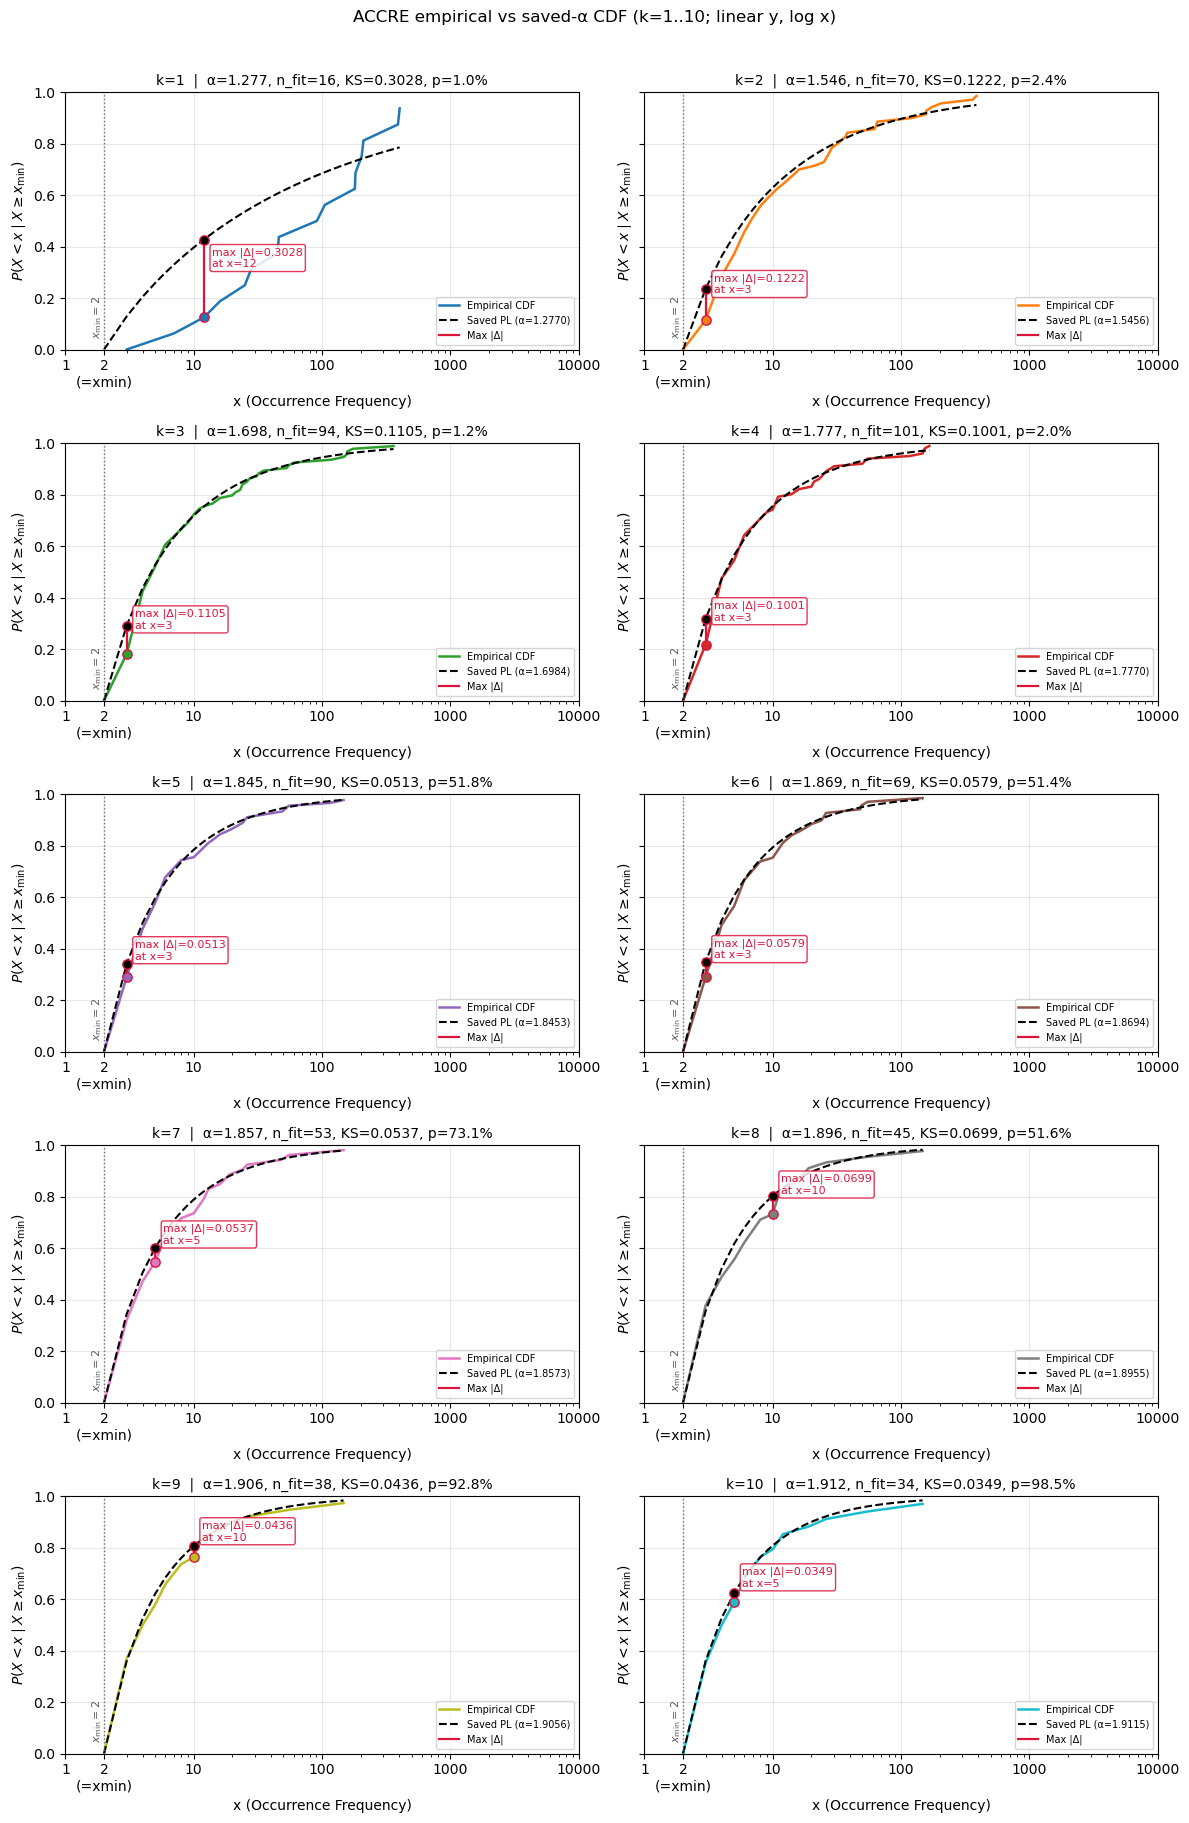

,k,x,delta,abs_delta,reported_KS_D,matches_KS_D
0,1,12.0,-0.302784,0.302784,0.302784,True
1,2,3.0,-0.122218,0.122218,0.122218,True
2,3,3.0,-0.110518,0.110518,0.110518,True
3,4,3.0,-0.100114,0.100114,0.100114,True
4,5,3.0,-0.051265,0.051265,0.051265,True
5,6,3.0,-0.057933,0.057933,0.057933,True
6,7,5.0,-0.053729,0.053729,0.053729,True
7,8,10.0,-0.069856,0.069856,0.069856,True
8,9,10.0,-0.043555,0.043555,0.043555,True
9,10,5.0,-0.034937,0.034937,0.034937,True


CDF max |Δ| matches reported KS_D for all plotted orders.


In [143]:
import matplotlib.ticker as mticker
PLOT_KS = list(range(1, 11))  # k=1..10
color4, color5 = "tab:blue", "tab:orange"
panel_colors = plt.cm.tab10.colors


def _max_deviation_point(kind: str, tail_data: np.ndarray, model, saved_xmin: int):
    """Return (x*, y_emp*, y_model*, residual) at max |emp − model| on fitted support."""
    if kind == "cdf":
        x, y_emp = powerlaw.cdf(tail_data, xmin=saved_xmin)
        y_model = np.asarray(model.cdf(np.asarray(x, dtype=float)), dtype=float)
    elif kind == "ccdf":
        x, y_emp = powerlaw.ccdf(tail_data, xmin=saved_xmin)
        y_model = np.asarray(model.ccdf(np.asarray(x, dtype=float)), dtype=float)
    else:
        raise ValueError(kind)
    x = np.asarray(x, dtype=float)
    y_emp = np.asarray(y_emp, dtype=float)
    resid = y_emp - y_model
    i_star = int(np.nanargmax(np.abs(resid)))
    return float(x[i_star]), float(y_emp[i_star]), float(y_model[i_star]), float(resid[i_star])


def _label_xmin_frequency(ax, saved_xmin: int, *, y_linear: bool, x_left: float = 1.0) -> None:
    """Mark the leftmost fitted frequency (= xmin) on the log-x axis."""
    saved_xmin = float(saved_xmin)
    ax.axvline(saved_xmin, color="0.45", ls=":", lw=1.0, zorder=2)
    ymin, ymax = ax.get_ylim()
    if y_linear:
        y_text = ymin + 0.04 * (ymax - ymin)
    else:
        y_text = ymin * ((ymax / ymin) ** 0.04) if ymin > 0 else ymax * 0.05
    ax.text(
        saved_xmin,
        y_text,
        f"$x_{{\mathrm{{min}}}}={int(saved_xmin)}$",
        rotation=90,
        va="bottom",
        ha="right",
        fontsize=8,
        color="0.35",
        clip_on=False,
    )
    # Keep only ticks at/above x_left so LogLocator decades like 0.1 do not widen the view.
    ticks = [t for t in ax.get_xticks() if np.isfinite(t) and t >= x_left]
    if not any(np.isclose(t, saved_xmin) for t in ticks):
        ticks = sorted(ticks + [saved_xmin])
    ax.set_xticks(ticks)

    def _fmt(x, _pos=None, xmin=saved_xmin):
        if not np.isfinite(x) or x <= 0:
            return ""
        if np.isclose(x, xmin):
            return f"{int(xmin)}\n(=xmin)"
        if abs(x - round(x)) < 1e-8:
            return str(int(round(x)))
        return f"{x:g}"

    ax.xaxis.set_major_formatter(mticker.FuncFormatter(_fmt))
    # Re-assert left edge after tick changes (matplotlib otherwise autoscales to ~0.1).
    _, x_right = ax.get_xlim()
    ax.set_xlim(x_left, max(x_right, saved_xmin * 1.01))
    ax.set_xmargin(0.0)

def plot_saved_pl_cdf(ax, frequencies: np.ndarray, saved_alpha: float, saved_xmin: float, *, color: str, title: str):
    """Empirical CDF + saved-parameter discrete PL CDF (no Fit / no MLE)."""
    frequencies = np.asarray(frequencies, dtype=int)
    saved_xmin = int(saved_xmin)
    tail_data = frequencies[frequencies >= saved_xmin]
    x_grid = np.arange(saved_xmin, int(tail_data.max()) + 1)

    powerlaw.plot_cdf(tail_data, ax=ax, color=color, linewidth=1.8, label="Empirical CDF")

    model = powerlaw.Power_Law(
        xmin=saved_xmin,
        parameters=[float(saved_alpha)],
        discrete=True,
    )
    model.plot_cdf(
        data=x_grid,
        ax=ax,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=f"Saved PL (α={float(saved_alpha):.4f})",
    )

    x_star, y_emp, y_model, resid = _max_deviation_point("cdf", tail_data, model, saved_xmin)
    ax.plot([x_star, x_star], [y_emp, y_model], color="crimson", lw=1.6, zorder=4, label="Max |Δ|")
    ax.scatter([x_star], [y_emp], color=color, s=45, zorder=5, edgecolor="crimson")
    ax.scatter([x_star], [y_model], color="black", s=45, zorder=5, edgecolor="crimson")
    ax.annotate(
        f"max |Δ|={abs(resid):.4f}\nat x={x_star:.0f}",
        xy=(x_star, 0.5 * (y_emp + y_model)),
        textcoords="offset points",
        xytext=(6, 8),
        fontsize=8,
        color="crimson",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="crimson", alpha=0.85),
    )

    ax.set_xscale("log")
    ax.set_yscale("linear")
    ax.set_ylim(0.0, 1.0)
    _label_xmin_frequency(ax, saved_xmin, y_linear=True, x_left=1.0)
    ax.set_xlabel("x (Occurrence Frequency)")
    ax.set_ylabel(r"$P(X < x \mid X \geq x_{\mathrm{min}})$")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=7, loc="lower right")
    ax.set_title(title, fontsize=10)
    ax.set_xlim(1.0, ax.get_xlim()[1])
    return model, {"x": x_star, "delta": resid, "abs_delta": abs(resid)}


n_panels = len(PLOT_KS)
n_cols = 2
n_rows = int(np.ceil(n_panels / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 3.6 * n_rows), sharex=False, sharey=True)
axes_flat = np.asarray(axes).ravel()

cdf_dev = {}
for i, k in enumerate(PLOT_KS):
    ax = axes_flat[i]
    concept = f"n{k}"
    rows = summary.loc[summary["concept"] == concept]
    if rows.empty or concept not in recovered:
        ax.set_visible(False)
        print(f"CDF k={k}: missing summary/attachments — skipped")
        continue
    csv_row = rows.iloc[0]
    saved_alpha = float(csv_row["alpha"])
    saved_xmin = float(csv_row["xmin"])
    color = panel_colors[i % len(panel_colors)]
    _, info = plot_saved_pl_cdf(
        ax,
        recovered[concept],
        saved_alpha,
        saved_xmin,
        color=color,
        title=(
            f"k={k}  |  α={saved_alpha:.3f}, "
            f"n_fit={int(csv_row['n_fitted_types'])}, "
            f"KS={float(csv_row['KS_D']):.4f}, "
            f"p={100.0 * float(csv_row['gof_p']):.1f}%"
        ),
    )
    ks = float(csv_row["KS_D"])
    info["reported_KS_D"] = ks
    info["matches_KS_D"] = bool(np.isclose(info["abs_delta"], ks, rtol=0, atol=1e-10))
    cdf_dev[k] = info
    match = "MATCH" if info["matches_KS_D"] else "MISMATCH"
    print(
        f"CDF k={k}: max |Δ|={info['abs_delta']:.6f} at x={info['x']:.0f}; "
        f"KS_D={ks:.6f}; |Δ|-KS_D={info['abs_delta']-ks:.3e} [{match}]"
    )

for j in range(n_panels, len(axes_flat)):
    axes_flat[j].set_visible(False)

fig.suptitle(
    f"{LOG_NAME} empirical vs saved-α CDF (k=1..10; linear y, log x)",
    y=1.01,
)
fig.tight_layout()
for _ax in np.atleast_1d(axes).ravel():
    _ax.set_xlim(1.0, max(_ax.get_xlim()[1], 1.0))
fig.savefig(FIG_DIR / "cdf_grid_k1_k10.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "cdf_grid_k1_k10.png", dpi=160, bbox_inches="tight")
plt.show()

cdf_dev_df = pd.DataFrame([{"k": k, **v} for k, v in cdf_dev.items()]).sort_values("k")
display(cdf_dev_df)
if len(cdf_dev_df) and cdf_dev_df["matches_KS_D"].all():
    print("CDF max |Δ| matches reported KS_D for all plotted orders.")
else:
    print("WARNING: CDF max |Δ| does not match KS_D for at least one order (or nothing plotted).")


### B. Empirical and fitted CCDFs (log–log)

Same inputs and no-refit construction as in A for $k=1\ldots10$, using `powerlaw.plot_ccdf` / `model.plot_ccdf(data=x_grid)`. Both axes logarithmic; two panels per row.

**Convention:** complementary to A, i.e. $P(X \ge x \mid X \ge x_{\min}) = 1 - P(X < x \mid X \ge x_{\min})$ (equals $1$ at $x=x_{\min}$).


CCDF k=1: max |Δ|=0.302784 at x=12; KS_D=0.302784; |Δ|-KS_D=0.000e+00 [MATCH]
CCDF k=2: max |Δ|=0.122218 at x=3; KS_D=0.122218; |Δ|-KS_D=2.776e-17 [MATCH]
CCDF k=3: max |Δ|=0.110518 at x=3; KS_D=0.110518; |Δ|-KS_D=5.551e-17 [MATCH]
CCDF k=4: max |Δ|=0.100114 at x=3; KS_D=0.100114; |Δ|-KS_D=-5.551e-17 [MATCH]
CCDF k=5: max |Δ|=0.051265 at x=3; KS_D=0.051265; |Δ|-KS_D=-5.551e-17 [MATCH]
CCDF k=6: max |Δ|=0.057933 at x=3; KS_D=0.057933; |Δ|-KS_D=-3.469e-17 [MATCH]
CCDF k=7: max |Δ|=0.053729 at x=5; KS_D=0.053729; |Δ|-KS_D=1.388e-16 [MATCH]
CCDF k=8: max |Δ|=0.069856 at x=10; KS_D=0.069856; |Δ|-KS_D=-2.220e-16 [MATCH]
CCDF k=9: max |Δ|=0.043555 at x=10; KS_D=0.043555; |Δ|-KS_D=7.633e-17 [MATCH]
CCDF k=10: max |Δ|=0.034937 at x=5; KS_D=0.034937; |Δ|-KS_D=6.939e-18 [MATCH]


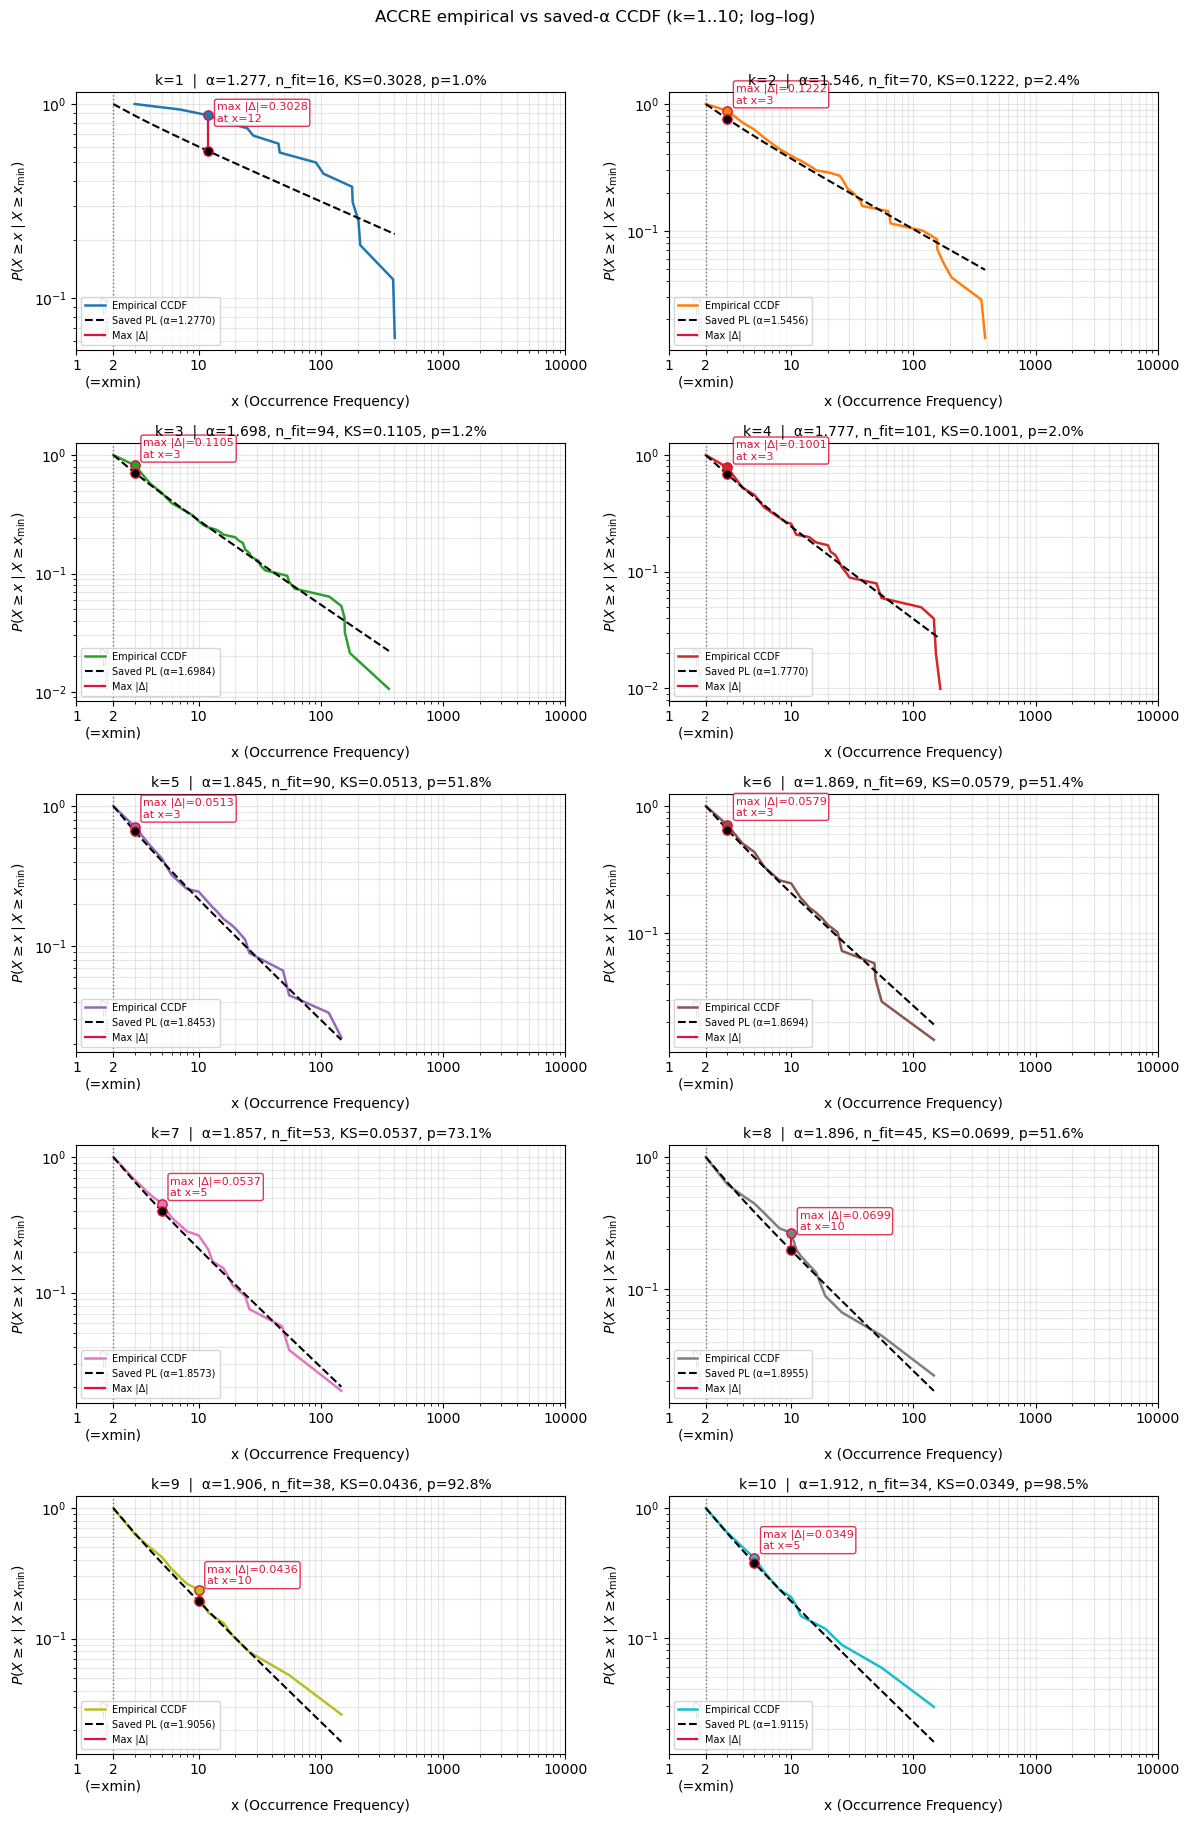

,k,x,delta,abs_delta,reported_KS_D,matches_KS_D
0,1,12.0,0.302784,0.302784,0.302784,True
1,2,3.0,0.122218,0.122218,0.122218,True
2,3,3.0,0.110518,0.110518,0.110518,True
3,4,3.0,0.100114,0.100114,0.100114,True
4,5,3.0,0.051265,0.051265,0.051265,True
5,6,3.0,0.057933,0.057933,0.057933,True
6,7,5.0,0.053729,0.053729,0.053729,True
7,8,10.0,0.069856,0.069856,0.069856,True
8,9,10.0,0.043555,0.043555,0.043555,True
9,10,5.0,0.034937,0.034937,0.034937,True


CCDF max |Δ| matches reported KS_D for all plotted orders.


In [144]:
def plot_saved_pl_ccdf(ax, frequencies: np.ndarray, saved_alpha: float, saved_xmin: float, *, color: str, title: str):
    """Empirical CCDF + saved-parameter discrete PL CCDF (no Fit / no MLE)."""
    frequencies = np.asarray(frequencies, dtype=int)
    saved_xmin = int(saved_xmin)
    tail_data = frequencies[frequencies >= saved_xmin]
    x_grid = np.arange(saved_xmin, int(tail_data.max()) + 1)

    powerlaw.plot_ccdf(tail_data, ax=ax, color=color, linewidth=1.8, label="Empirical CCDF")

    model = powerlaw.Power_Law(
        xmin=saved_xmin,
        parameters=[float(saved_alpha)],
        discrete=True,
    )
    model.plot_ccdf(
        data=x_grid,
        ax=ax,
        color="black",
        linestyle="--",
        linewidth=1.5,
        label=f"Saved PL (α={float(saved_alpha):.4f})",
    )

    x_star, y_emp, y_model, resid = _max_deviation_point("ccdf", tail_data, model, saved_xmin)
    y0, y1 = max(y_emp, 1e-16), max(y_model, 1e-16)
    ax.plot([x_star, x_star], [y0, y1], color="crimson", lw=1.6, zorder=4, label="Max |Δ|")
    ax.scatter([x_star], [y0], color=color, s=45, zorder=5, edgecolor="crimson")
    ax.scatter([x_star], [y1], color="black", s=45, zorder=5, edgecolor="crimson")
    ax.annotate(
        f"max |Δ|={abs(resid):.4f}\nat x={x_star:.0f}",
        xy=(x_star, np.sqrt(y0 * y1)),
        textcoords="offset points",
        xytext=(6, 8),
        fontsize=8,
        color="crimson",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="crimson", alpha=0.85),
    )

    ax.set_xscale("log")
    ax.set_yscale("log")
    _label_xmin_frequency(ax, saved_xmin, y_linear=False, x_left=1.0)
    ax.set_xlabel("x (Occurrence Frequency)")
    ax.set_ylabel(r"$P(X \geq x \mid X \geq x_{\mathrm{min}})$")
    ax.grid(True, alpha=0.3, which="both")
    ax.legend(fontsize=7, loc="lower left")
    ax.set_title(title, fontsize=10)
    ax.set_xlim(1.0, ax.get_xlim()[1])
    return model, {"x": x_star, "delta": resid, "abs_delta": abs(resid)}


n_panels = len(PLOT_KS)
n_cols = 2
n_rows = int(np.ceil(n_panels / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 3.6 * n_rows), sharex=False, sharey=False)
axes_flat = np.asarray(axes).ravel()

ccdf_dev = {}
for i, k in enumerate(PLOT_KS):
    ax = axes_flat[i]
    concept = f"n{k}"
    rows = summary.loc[summary["concept"] == concept]
    if rows.empty or concept not in recovered:
        ax.set_visible(False)
        print(f"CCDF k={k}: missing summary/attachments — skipped")
        continue
    csv_row = rows.iloc[0]
    saved_alpha = float(csv_row["alpha"])
    saved_xmin = float(csv_row["xmin"])
    color = panel_colors[i % len(panel_colors)]
    _, info = plot_saved_pl_ccdf(
        ax,
        recovered[concept],
        saved_alpha,
        saved_xmin,
        color=color,
        title=(
            f"k={k}  |  α={saved_alpha:.3f}, "
            f"n_fit={int(csv_row['n_fitted_types'])}, "
            f"KS={float(csv_row['KS_D']):.4f}, "
            f"p={100.0 * float(csv_row['gof_p']):.1f}%"
        ),
    )
    ks = float(csv_row["KS_D"])
    info["reported_KS_D"] = ks
    info["matches_KS_D"] = bool(np.isclose(info["abs_delta"], ks, rtol=0, atol=1e-10))
    ccdf_dev[k] = info
    match = "MATCH" if info["matches_KS_D"] else "MISMATCH"
    print(
        f"CCDF k={k}: max |Δ|={info['abs_delta']:.6f} at x={info['x']:.0f}; "
        f"KS_D={ks:.6f}; |Δ|-KS_D={info['abs_delta']-ks:.3e} [{match}]"
    )

for j in range(n_panels, len(axes_flat)):
    axes_flat[j].set_visible(False)

fig.suptitle(
    f"{LOG_NAME} empirical vs saved-α CCDF (k=1..10; log–log)",
    y=1.01,
)
fig.tight_layout()
for _ax in np.atleast_1d(axes).ravel():
    _ax.set_xlim(1.0, max(_ax.get_xlim()[1], 1.0))
fig.savefig(FIG_DIR / "ccdf_grid_k1_k10.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "ccdf_grid_k1_k10.png", dpi=160, bbox_inches="tight")
plt.show()

ccdf_dev_df = pd.DataFrame([{"k": k, **v} for k, v in ccdf_dev.items()]).sort_values("k")
display(ccdf_dev_df)
if len(ccdf_dev_df) and ccdf_dev_df["matches_KS_D"].all():
    print("CCDF max |Δ| matches reported KS_D for all plotted orders.")
else:
    print("WARNING: CCDF max |Δ| does not match KS_D for at least one order (or nothing plotted).")


### C. CCDF residuals (saved α)

Compare empirical fitted-tail CCDF to the saved-α model on a shared integer support. Max $|$residual$|$ should match reported `KS_D`.


,k,saved_alpha,x_at_max_|residual|,empirical_CCDF,model_CCDF,residual,abs_residual,reported_KS_D,matches_KS_D,abs_diff_vs_KS_D
0,4,1.776979,3.0,0.782178,0.682064,0.100114,0.100114,0.100114,True,5.551115e-17
1,5,1.845306,3.0,0.711111,0.659846,0.051265,0.051265,0.051265,True,5.551115e-17


Max |empirical CCDF − saved-α model CCDF| reproduces reported KS_D for both orders.


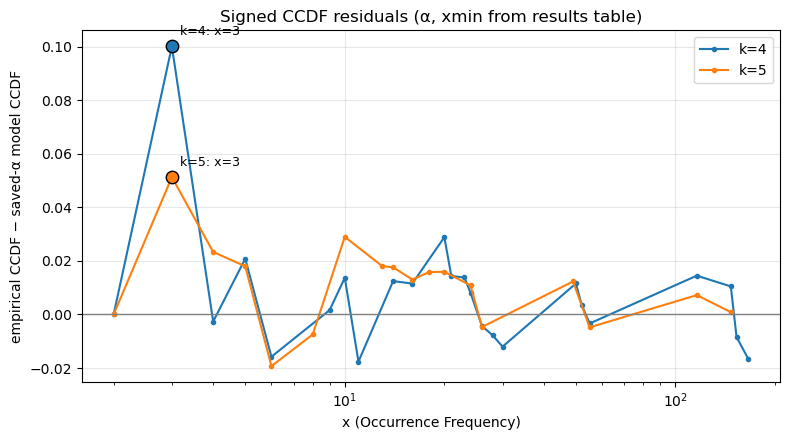

,k,saved_alpha,x_at_max_|residual|,empirical_CCDF,model_CCDF,residual,abs_residual,reported_KS_D,matches_KS_D,abs_diff_vs_KS_D
0,4,1.776979,3.0,0.782178,0.682064,0.100114,0.100114,0.100114,True,5.551115e-17
1,5,1.845306,3.0,0.711111,0.659846,0.051265,0.051265,0.051265,True,5.551115e-17


In [145]:
def library_ccdfs_from_table(freqs: np.ndarray, saved_alpha: float, saved_xmin: int = FIXED_XMIN):
    """Empirical CCDF from data + model CCDF from saved α (no new MLE)."""
    saved_xmin = int(saved_xmin)
    tail_data = np.asarray(freqs, dtype=int)
    tail_data = tail_data[tail_data >= saved_xmin]
    x, ccdf_emp = powerlaw.ccdf(tail_data, xmin=saved_xmin)
    x = np.asarray(x, dtype=float)
    ccdf_emp = np.asarray(ccdf_emp, dtype=float)
    model = powerlaw.Power_Law(
        xmin=saved_xmin,
        parameters=[float(saved_alpha)],
        discrete=True,
    )
    ccdf_model = np.asarray(model.ccdf(x), dtype=float)
    return x, ccdf_emp, ccdf_model


residual_info = []
for k in (K_BEFORE, K_AFTER):
    concept = f"n{k}"
    csv_row = summary.loc[summary["concept"] == concept].iloc[0]
    saved_alpha = float(csv_row["alpha"])
    x, ccdf_e, ccdf_m = library_ccdfs_from_table(
        recovered[concept], saved_alpha, int(csv_row["xmin"])
    )
    resid = ccdf_e - ccdf_m
    i_star = int(np.nanargmax(np.abs(resid)))
    max_abs = float(np.abs(resid[i_star]))
    ks = float(csv_row["KS_D"])
    residual_info.append({
        "k": k,
        "saved_alpha": saved_alpha,
        "x_at_max_|residual|": float(x[i_star]),
        "empirical_CCDF": float(ccdf_e[i_star]),
        "model_CCDF": float(ccdf_m[i_star]),
        "residual": float(resid[i_star]),
        "abs_residual": max_abs,
        "reported_KS_D": ks,
        "matches_KS_D": bool(np.isclose(max_abs, ks, rtol=0, atol=1e-10)),
        "abs_diff_vs_KS_D": abs(max_abs - ks),
    })

residual_check_df = pd.DataFrame(residual_info)
display(residual_check_df)
if residual_check_df["matches_KS_D"].all():
    print("Max |empirical CCDF − saved-α model CCDF| reproduces reported KS_D for both orders.")
else:
    print("WARNING: max |CCDF residual| does not match reported KS_D.")
    display(residual_check_df.loc[~residual_check_df["matches_KS_D"]])

fig, ax = plt.subplots(figsize=(8, 4.5))
for k, color in [(K_BEFORE, color4), (K_AFTER, color5)]:
    concept = f"n{k}"
    csv_row = summary.loc[summary["concept"] == concept].iloc[0]
    x, ccdf_e, ccdf_m = library_ccdfs_from_table(
        recovered[concept], float(csv_row["alpha"]), int(csv_row["xmin"])
    )
    resid = ccdf_e - ccdf_m
    ax.plot(x, resid, "-o", color=color, ms=3, label=f"k={k}")
    i_star = int(np.nanargmax(np.abs(resid)))
    ax.scatter([x[i_star]], [resid[i_star]], color=color, s=80, zorder=5, edgecolor="black")
    ax.annotate(
        f"k={k}: x={x[i_star]:.0f}",
        (x[i_star], resid[i_star]),
        textcoords="offset points",
        xytext=(6, 8),
        fontsize=9,
    )

ax.axhline(0, color="gray", lw=1)
ax.set_xscale("log")
ax.set_xlabel("x (Occurrence Frequency)")
ax.set_ylabel("empirical CCDF − saved-α model CCDF")
ax.set_title("Signed CCDF residuals (α, xmin from results table)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "ccdf_residuals_k4_k5.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "ccdf_residuals_k4_k5.png", dpi=160, bbox_inches="tight")
plt.show()

residual_df = residual_check_df.copy()
display(residual_df)
residual_df.to_csv(FIG_DIR / "ccdf_residual_maxima.csv", index=False)


## 5. Distributional change via Earth Mover’s Distance (1-Wasserstein)

Each distinct behavioral type is one equally weighted observation (the type’s frequency value). We do **not** re-weight by occurrence count.

- **Raw-frequency EMD** emphasizes absolute frequency differences.
- **Log-frequency EMD** measures differences on a multiplicative scale ($\log$ frequencies).

A large empirical shift does not imply a worse power-law fit: two different distributions can both be close to (different) power laws.


In [146]:
def emd_pair(a: np.ndarray, b: np.ndarray) -> dict:
    a = np.asarray(a, dtype=float)
    b = np.asarray(b, dtype=float)
    a_tail = a[a >= FIXED_XMIN]
    b_tail = b[b >= FIXED_XMIN]
    return {
        "emd_full_raw": float(wasserstein_distance(a, b)),
        "emd_full_log": float(wasserstein_distance(np.log(a), np.log(b))),
        "emd_tail_raw": float(wasserstein_distance(a_tail, b_tail)),
        "emd_tail_log": float(wasserstein_distance(np.log(a_tail), np.log(b_tail))),
    }


ngram_concepts = [c for c in summary["concept"] if k_from_concept(c) is not None]
ngram_concepts = sorted(ngram_concepts, key=concept_sort_key)

adj_rows = []
for c_before, c_after in zip(ngram_concepts[:-1], ngram_concepts[1:]):
    k_b, k_a = k_from_concept(c_before), k_from_concept(c_after)
    if c_before not in recovered or c_after not in recovered:
        continue
    row_b = summary.loc[summary["concept"] == c_before].iloc[0]
    row_a = summary.loc[summary["concept"] == c_after].iloc[0]
    emd = emd_pair(recovered[c_before], recovered[c_after])
    gof_b, gof_a = float(row_b["gof_p"]), float(row_a["gof_p"])
    nfit_b, nfit_a = int(row_b["n_fitted_types"]), int(row_a["n_fitted_types"])
    ks_b, ks_a = float(row_b["KS_D"]), float(row_a["KS_D"])
    adj_rows.append({
        "k_before": k_b,
        "k_after": k_a,
        **emd,
        "KS_before": ks_b,
        "KS_after": ks_a,
        "KS_diff": ks_a - ks_b,
        "gof_p_before": gof_b,
        "gof_p_after": gof_a,
        "n_fitted_before": nfit_b,
        "n_fitted_after": nfit_a,
        "gof_crosses_0.10": (gof_b < 0.10) != (gof_a < 0.10),
        "both_eligible_nfit>=30": (nfit_b >= 30) and (nfit_a >= 30),
        "is_focus_4_to_5": (k_b == K_BEFORE and k_a == K_AFTER),
    })

adj_df = pd.DataFrame(adj_rows)

def highlight_focus(row):
    return ["background-color: #fff3cd" if row["is_focus_4_to_5"] else "" for _ in row]

display(
    adj_df.style.apply(highlight_focus, axis=1).format({
        "emd_full_raw": "{:.4f}",
        "emd_full_log": "{:.4f}",
        "emd_tail_raw": "{:.4f}",
        "emd_tail_log": "{:.4f}",
        "KS_before": "{:.4f}",
        "KS_after": "{:.4f}",
        "KS_diff": "{:.4f}",
        "gof_p_before": "{:.4f}",
        "gof_p_after": "{:.4f}",
    })
)
adj_df.to_csv(FIG_DIR / "adjacent_order_emd.csv", index=False)

focus = adj_df.loc[adj_df["is_focus_4_to_5"]].iloc[0]
print(
    f"Focus k=4→5: EMD_full_raw={focus['emd_full_raw']:.4f}, "
    f"EMD_tail_log={focus['emd_tail_log']:.4f}, "
    f"KS {focus['KS_before']:.4f}→{focus['KS_after']:.4f}, "
    f"p {focus['gof_p_before']:.4f}→{focus['gof_p_after']:.4f}, "
    f"crosses 0.10={focus['gof_crosses_0.10']}"
)


,k_before,k_after,emd_full_raw,emd_full_log,emd_tail_raw,emd_tail_log,KS_before,KS_after,KS_diff,gof_p_before,gof_p_after,n_fitted_before,n_fitted_after,gof_crosses_0.10,both_eligible_nfit>=30,is_focus_4_to_5
0,1,2,97.6543,2.4183,88.4911,1.7688,0.3028,0.1222,-0.1806,0.0096,0.0244,16,70,False,False,False
1,2,3,11.4402,0.4929,13.0395,0.3965,0.1222,0.1105,-0.0117,0.0244,0.0116,70,94,False,True,False
2,3,4,4.0277,0.1789,5.4775,0.1425,0.1105,0.1001,-0.0104,0.0116,0.0204,94,101,False,True,False
3,4,5,2.4864,0.1986,2.8211,0.1021,0.1001,0.0513,-0.0488,0.0204,0.5176,101,90,True,True,True
4,5,6,1.6096,0.1500,1.9401,0.0456,0.0513,0.0579,0.0067,0.5176,0.5140,90,69,False,True,False
5,6,7,0.4408,0.0795,0.8220,0.0539,0.0579,0.0537,-0.0042,0.5140,0.7312,69,53,False,True,False
6,7,8,0.3625,0.0264,1.0973,0.0686,0.0537,0.0699,0.0161,0.7312,0.5156,53,45,False,True,False
7,8,9,0.3269,0.0190,0.9825,0.0533,0.0699,0.0436,-0.0263,0.5156,0.9280,45,38,False,True,False
8,9,10,0.2584,0.0154,0.8019,0.0451,0.0436,0.0349,-0.0086,0.9280,0.9848,38,34,False,True,False
9,10,11,0.2619,0.0224,0.8330,0.0697,0.0349,0.0538,0.0188,0.9848,0.8920,34,31,False,True,False


Focus k=4→5: EMD_full_raw=2.4864, EMD_tail_log=0.1021, KS 0.1001→0.0513, p 0.0204→0.5176, crosses 0.10=True


## 6. Representation-induced weighting effects (from the ACCRE log)

In [147]:
# Reuse ACCRE traces loaded for the length plots above (reload if needed).
from collections import Counter

if "trace_rows" not in globals():
    data_dictionary = get_data_dictionary(DATA_DICTIONARY, get_real=True, get_synthetic=False)
    event_log = get_event_log_from_dictionary(LOG_NAME, data_dictionary)
    trace_rows = trace_completion_data(event_log)
print(f"Loaded {LOG_NAME}: {len(trace_rows)} traces with completion timestamps")

# Variant table: activity sequence -> multiplicity and length

variant_counter = Counter(tuple(row["activity_sequence"]) for row in trace_rows)
variants = pd.DataFrame([
    {"variant": v, "c_v": c, "l_v": len(v)}
    for v, c in variant_counter.items()
])
variants["case_share"] = variants["c_v"] / variants["c_v"].sum()
print(variants[["c_v", "l_v"]].describe())


Loaded ACCRE: 398 traces with completion timestamps
              c_v        l_v
count   65.000000  65.000000
mean     6.123077   6.969231
std     19.365326   3.010239
min      1.000000   1.000000
25%      1.000000   5.000000
50%      1.000000   7.000000
75%      4.000000   8.000000
max    147.000000  21.000000


### A. Complete-trace coverage

Implementation (`utils/io/attachments.py::_ngram_nodes`): for $k\ge 2$ with START/END pads, the working sequence has length $\ell+2$. If $k \ge \ell+2$ (i.e. $\ell+2 \le k$), the **entire** padded sequence is emitted as one node — the complete-trace case. Equivalently: `trace_length + 2 <= k`.


In [148]:
def is_complete_trace(l_v: int, k: int) -> bool:
    """True iff n-gram extraction emits the whole padded trace as one node."""
    if k == 1:
        return False  # n1 never wraps; never a single complete-trace token for k=1
    return (l_v + 2) <= k


def observation_contribution(c_v: int, l_v: int, k: int) -> int:
    """Match attachments extraction counting.

    k=1: c_v * l_v
    k>=2: c_v * max(1, l_v + 3 - k)  == sliding windows on (START,*seq,END),
          or 1 when the whole padded trace is emitted.
    """
    if k == 1:
        return int(c_v * l_v)
    return int(c_v * max(1, l_v + 3 - k))


# Verify contribution formula against stored attachments totals
contrib_check = []
for concept in ngram_concepts:
    k = k_from_concept(concept)
    pred = int(sum(observation_contribution(int(r.c_v), int(r.l_v), k) for r in variants.itertuples()))
    actual_occ = int(summary.loc[summary["concept"] == concept, "n_occurrences"].iloc[0])
    contrib_check.append({
        "concept": concept,
        "k": k,
        "predicted_occurrences": pred,
        "csv_n_occurrences": actual_occ,
        "match": pred == actual_occ,
    })
contrib_check_df = pd.DataFrame(contrib_check)
display(contrib_check_df)
assert contrib_check_df["match"].all(), "Contribution formula does not reproduce attachment totals"

coverage_rows = []
total_cases = int(variants["c_v"].sum())
n_variants = len(variants)
for k in sorted({k_from_concept(c) for c in ngram_concepts}):
    complete_mask = variants["l_v"].map(lambda L: is_complete_trace(int(L), k))
    coverage_rows.append({
        "k": k,
        "frac_case_occurrences_complete": float(variants.loc[complete_mask, "c_v"].sum() / total_cases),
        "frac_variants_complete": float(complete_mask.mean()),
        "n_complete_variants": int(complete_mask.sum()),
    })
coverage_df = pd.DataFrame(coverage_rows)
display(coverage_df)
display(coverage_df.loc[coverage_df["k"].isin([K_BEFORE, K_AFTER])])


,concept,k,predicted_occurrences,csv_n_occurrences,match
0,n1,1,1945,1945,True
1,n2,2,2343,2343,True
2,n3,3,1945,1945,True
3,n4,4,1553,1553,True
4,n5,5,1161,1161,True
5,n6,6,795,795,True
6,n7,7,659,659,True
7,n8,8,547,547,True
8,n9,9,481,481,True
9,n10,10,443,443,True


,k,frac_case_occurrences_complete,frac_variants_complete,n_complete_variants
0,1,0.000000,0.000000,0
1,2,0.000000,0.000000,0
2,3,0.015075,0.015385,1
3,4,0.015075,0.015385,1
4,5,0.080402,0.030769,2
5,6,0.658291,0.169231,11
6,7,0.718593,0.292308,19
7,8,0.834171,0.492308,32
8,9,0.904523,0.676923,44
9,10,0.967337,0.815385,53


,k,frac_case_occurrences_complete,frac_variants_complete,n_complete_variants
3,4,0.015075,0.015385,1
4,5,0.080402,0.030769,2


### B. Observation contributions by trace-length group

Case-length edges: q25=4.0, q50=4.0, q75=6.0, p90=7.0. Longest ~10%: L >= p90 (ties at the threshold included).


,case_share,obs_share_k4,obs_share_k5
length_group,,,
Q1 (shortest ~25%),0.658291,0.481648,0.423773
Q3 (~50-75%),0.175879,0.209916,0.220500
longest ~10% (L >= p90),0.165829,0.308435,0.355728


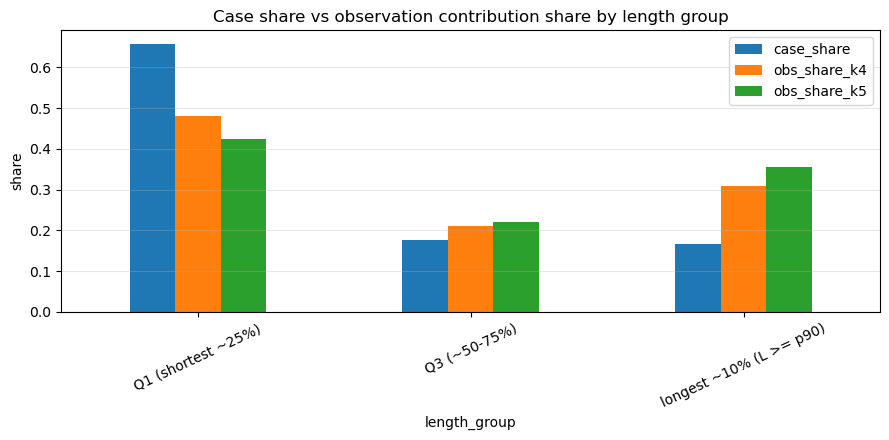

In [149]:
# Fixed length groups from the original log (membership unchanged across k).
# Edges are computed once from the case-length distribution (each case once).
case_lengths = np.repeat(variants["l_v"].to_numpy(), variants["c_v"].to_numpy())
q25, q50, q75, thr = np.quantile(case_lengths, [0.25, 0.50, 0.75, 0.90])
print(
    f"Case-length edges: q25={q25}, q50={q50}, q75={q75}, p90={thr}. "
    "Longest ~10%: L >= p90 (ties at the threshold included)."
)

def length_group(L: int) -> str:
    L = int(L)
    if L <= q25:
        return "Q1 (shortest ~25%)"
    if L <= q50:
        return "Q2 (~25-50%)"
    if L <= q75:
        return "Q3 (~50-75%)"
    if L < thr:
        return "Q4 (~75% to <p90)"
    return "longest ~10% (L >= p90)"

variants = variants.copy()
variants["length_group"] = variants["l_v"].map(lambda L: length_group(int(L)))

group_case_share = (
    variants.groupby("length_group")["c_v"].sum() / total_cases
).rename("case_share")

group_tables = []
for k in (K_BEFORE, K_AFTER):
    contrib = variants.apply(
        lambda r: observation_contribution(int(r.c_v), int(r.l_v), k), axis=1
    )
    total = contrib.sum()
    g = (
        variants.assign(contrib=contrib)
        .groupby("length_group")["contrib"].sum() / total
    ).rename(f"obs_share_k{k}")
    group_tables.append(g)

group_cmp = pd.concat([group_case_share, *group_tables], axis=1).fillna(0.0)
display(group_cmp)
group_cmp.to_csv(FIG_DIR / "length_group_observation_shares.csv")

ax = group_cmp.plot(kind="bar", figsize=(9, 4.5), rot=25)
ax.set_ylabel("share")
ax.set_title("Case share vs observation contribution share by length group")
ax.grid(True, axis="y", alpha=0.3)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(FIG_DIR / "length_group_shares_k4_k5.pdf", bbox_inches="tight")
plt.show()


### C. Contribution concentration across trace variants

For variant $v$ with multiplicity $c_v$ and length $\ell_v$:

- $k=1$: $C_v(k)=c_v\cdot \ell_v$
- $k\ge 2$: $C_v(k)=c_v\cdot \max(1,\ell_v+3-k)$

Shares $q_v(k)=C_v(k)/\sum C$ are **observation contribution shares**. Shared behavioral types across variants still merge when aggregating to type frequencies.


In [150]:
def shannon_entropy(shares: np.ndarray) -> float:
    p = shares[shares > 0]
    return float(-np.sum(p * np.log(p)))


conc_rows = []
# Complete-trace baseline: shares = case frequencies / n_cases
base_shares = variants["case_share"].to_numpy()
base_H = shannon_entropy(base_shares)
conc_rows.append({
    "k": "baseline_complete_trace_case_shares",
    "entropy": base_H,
    "effective_n_variants": float(np.exp(base_H)),
    "n_positive_contributors": int(np.sum(base_shares > 0)),
})

for k in sorted({k_from_concept(c) for c in ngram_concepts}):
    C = variants.apply(lambda r: observation_contribution(int(r.c_v), int(r.l_v), k), axis=1).to_numpy(dtype=float)
    assert int(C.sum()) == int(summary.loc[summary["concept"] == f"n{k}", "n_occurrences"].iloc[0])
    q = C / C.sum()
    H = shannon_entropy(q)
    conc_rows.append({
        "k": k,
        "entropy": H,
        "effective_n_variants": float(np.exp(H)),
        "n_positive_contributors": int(np.sum(q > 0)),
    })

conc_df = pd.DataFrame(conc_rows)
display(conc_df)
display(conc_df.loc[conc_df["k"].isin([K_BEFORE, K_AFTER, "baseline_complete_trace_case_shares"])])
conc_df.to_csv(FIG_DIR / "contribution_concentration.csv", index=False)


,k,entropy,effective_n_variants,n_positive_contributors
0,baseline_complete_trace_case_shares,2.747262,15.599860,65
1,1,3.077531,21.704740,65
2,2,3.030263,20.702680,65
3,3,3.077531,21.704740,65
4,4,3.153174,23.410262,65
5,5,3.265545,26.194387,65
6,6,3.456248,31.697807,65
7,7,3.340546,28.234543,65
8,8,3.197871,24.480349,65
9,9,3.062555,21.382113,65


,k,entropy,effective_n_variants,n_positive_contributors
0,baseline_complete_trace_case_shares,2.747262,15.599860,65
4,4,3.153174,23.410262,65
5,5,3.265545,26.194387,65


### D. Within-case repetition (diagnostic only)

$1 - \frac{\sum_c \#\{\text{distinct behavioral types in case }c\}}{\sum_c \#\{\text{behavioral occurrences in case }c\}}$

Main analysis keeps occurrence-based counting; this only measures deduplication pressure.


In [151]:
rep_rows = []
for k in (K_BEFORE, K_AFTER):
    distinct_sum = 0
    occ_sum = 0
    for row in trace_rows:
        seq = tuple(row["activity_sequence"])
        nodes = _ngram_nodes(seq, k, add_start_end=True)
        occ_sum += len(nodes)
        distinct_sum += len(set(nodes))
    rep_rows.append({
        "k": k,
        "sum_distinct_types_per_case": distinct_sum,
        "sum_occurrences_per_case": occ_sum,
        "within_case_repetition": 1.0 - distinct_sum / occ_sum,
    })
rep_df = pd.DataFrame(rep_rows)
display(rep_df)


,k,sum_distinct_types_per_case,sum_occurrences_per_case,within_case_repetition
0,4,1552,1553,0.000644
1,5,1161,1161,0.000000


### E. Resulting support across orders

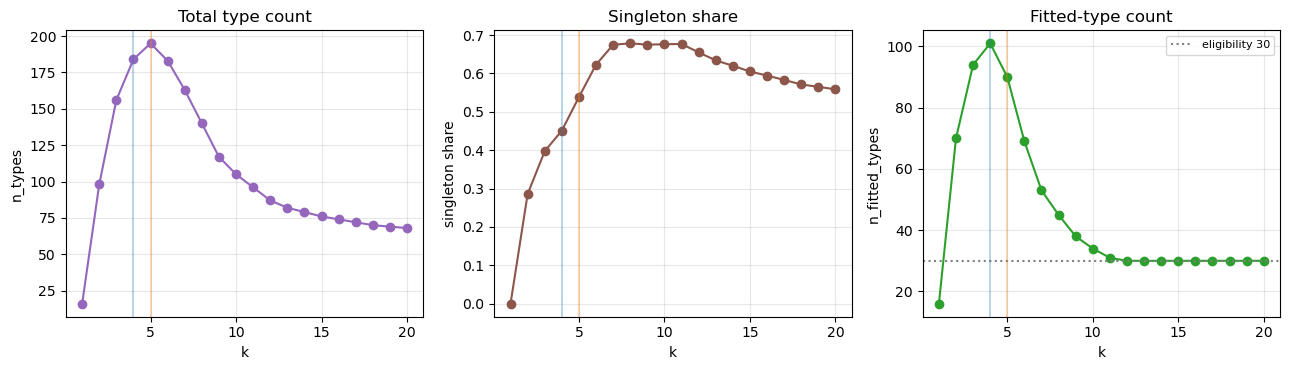

These support diagnostics co-move with the frequency-distribution changes (more singletons / fewer fitted types as k grows) but do not by themselves establish a causal explanation for the GOF jump.


In [152]:
support = summary.loc[summary["concept"].isin(ngram_concepts), [
    "concept", "n_types", "singleton_share", "n_fitted_types", "gof_p", "KS_D"
]].copy()
support["k"] = support["concept"].map(k_from_concept)
support = support.sort_values("k")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True)
axes[0].plot(support["k"], support["n_types"], "o-", color="tab:purple")
axes[0].set_ylabel("n_types")
axes[0].set_title("Total type count")
axes[1].plot(support["k"], support["singleton_share"], "o-", color="tab:brown")
axes[1].set_ylabel("singleton share")
axes[1].set_title("Singleton share")
axes[2].plot(support["k"], support["n_fitted_types"], "o-", color="tab:green")
axes[2].axhline(30, color="gray", ls=":", label="eligibility 30")
axes[2].set_ylabel("n_fitted_types")
axes[2].set_title("Fitted-type count")
axes[2].legend(fontsize=8)
for ax in axes:
    ax.axvline(K_BEFORE, color=color4, alpha=0.3)
    ax.axvline(K_AFTER, color=color5, alpha=0.3)
    ax.set_xlabel("k")
    ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / "support_across_orders.pdf", bbox_inches="tight")
plt.show()

print(
    "These support diagnostics co-move with the frequency-distribution changes "
    "(more singletons / fewer fitted types as k grows) but do not by themselves "
    "establish a causal explanation for the GOF jump."
)


## 6B. Type and occurrence transitions across abstraction orders

This overview tracks **all** behavioral types (including singletons), before any `xmin` filter, as the abstraction order increases $k \to k+1$.

**Parent rule (right extension).** Each $(k+1)$-gram occurrence is linked to the unique $k$-gram that is its **prefix**, using the same case and window start as in `_ngram_nodes` (not string containment alone). Short traces that already emit as a single boundary-marked complete node are **retained unchanged** when they remain saturated.

**$k=1\to 2$.** `n1` has no `START`/`END`. Every `START`-prefixed 2-gram therefore has no activity parent and is counted as an **introduced** type/occurrence.

**Source-type categories (partition).** Each source type falls in exactly one of: Extended $1\to 1$, Extended $1\to\mathrm{many}$, Newly completed $1\to 1$, Exhausted $1\to 0$, Complete and retained $1\to 1$. Introduced targets and newly complete target types are reported as diagnostics, not as extra source categories.

**Scope.** This quantifies branching, exhaustion, and saturation. It does **not** by itself explain doubleton-share or power-law GOF changes — those need child-frequency structure. No power-law refits or GOF bootstraps are run here.


In [153]:
# --- Transition accounting (all types; occurrence-identity right-extension parents) ---
from collections import Counter, defaultdict

assert "trace_rows" in globals() and len(trace_rows) > 0, "Load ACCRE traces first (section 1 / length plot)."
assert "is_complete_trace" in globals(), "Run section 6A first (is_complete_trace)."
if "ngram_concepts" not in globals():
    ngram_concepts = sorted(
        [c for c in summary["concept"] if k_from_concept(c) is not None],
        key=concept_sort_key,
    )
    print(f"Defined ngram_concepts from summary ({len(ngram_concepts)} concepts).")

SOURCE_CATS = [
    "Extended 1→1",
    "Extended 1→many",
    "Newly completed 1→1",
    "Exhausted 1→0",
    "Complete and retained 1→1",
]


def _emit_occurrences(case_id: int, seq: tuple[str, ...], k: int) -> list[dict]:
    """Match `_ngram_nodes` emissions, with case/position identity and completeness."""
    work = _extended_trace(seq, k, True)
    if k == 1:
        return [
            {
                "case_id": case_id,
                "pos": i,
                "node_id": str(activity),
                "is_complete": False,
                "tokens": (activity,),
            }
            for i, activity in enumerate(work)
        ]
    if k >= len(work):
        return [
            {
                "case_id": case_id,
                "pos": 0,
                "node_id": str(work),
                "is_complete": True,
                "tokens": tuple(work),
            }
        ]
    return [
        {
            "case_id": case_id,
            "pos": i,
            "node_id": str(work[i : i + k]),
            "is_complete": False,
            "tokens": tuple(work[i : i + k]),
        }
        for i in range(len(work) - k + 1)
    ]


def _classify_source_type(
    *,
    n_children: int,
    child_ids: set[str],
    src_is_complete: bool,
    tgt_complete_types: set[str],
) -> str:
    if n_children == 0:
        return "Exhausted 1→0"
    if n_children == 1:
        kid = next(iter(child_ids))
        kid_complete = kid in tgt_complete_types
        if src_is_complete and kid_complete:
            return "Complete and retained 1→1"
        if (not src_is_complete) and kid_complete:
            return "Newly completed 1→1"
        return "Extended 1→1"
    return "Extended 1→many"


def analyze_transition(k: int, sequences: list[tuple[str, ...]]) -> dict:
    """Right-extension parent map for k → k+1; return counts and validation payload."""
    src: list[dict] = []
    tgt: list[dict] = []
    for cid, seq in enumerate(sequences):
        src.extend(_emit_occurrences(cid, seq, k))
        tgt.extend(_emit_occurrences(cid, seq, k + 1))

    src_by_pos = {(o["case_id"], o["pos"]): o for o in src}
    src_by_case: dict[int, list[dict]] = defaultdict(list)
    for o in src:
        src_by_case[o["case_id"]].append(o)

    parent_children: dict[str, set[str]] = defaultdict(set)
    parent_child_occ: Counter = Counter()
    src_successor_keys: set[tuple[int, int]] = set()
    introduced_type_set: set[str] = set()
    introduced_occ = 0
    tgt_parent_types: dict[str, set[str]] = defaultdict(set)
    orphan_tgt = []
    # per source occ key: whether mapped
    for t in tgt:
        cid = t["case_id"]
        seq = sequences[cid]
        parent = None
        if k == 1:
            pref = t["tokens"][0]
            if pref == START:
                introduced_occ += 1
                introduced_type_set.add(t["node_id"])
                continue
            # Child sits on padded work; activity prefix aligns to n1 position pos-1.
            parent = src_by_pos.get((cid, t["pos"] - 1))
        else:
            src_complete = [o for o in src_by_case[cid] if o["is_complete"]]
            if t["is_complete"] and src_complete:
                parent = src_complete[0]
            elif t["is_complete"]:
                # Newly saturated whole-trace node: prefix parent is window at pos 0.
                parent = src_by_pos.get((cid, 0))
            else:
                parent = src_by_pos.get((cid, t["pos"]))

        if parent is None:
            orphan_tgt.append(t)
            continue
        parent_children[parent["node_id"]].add(t["node_id"])
        parent_child_occ[parent["node_id"]] += 1
        src_successor_keys.add((parent["case_id"], parent["pos"]))
        tgt_parent_types[t["node_id"]].add(parent["node_id"])

    src_types = {o["node_id"] for o in src}
    tgt_types = {o["node_id"] for o in tgt}
    src_complete_types = {o["node_id"] for o in src if o["is_complete"]}
    tgt_complete_types = {o["node_id"] for o in tgt if o["is_complete"]}
    src_occ_by_type = Counter(o["node_id"] for o in src)
    src_no_succ_by_type = Counter(
        o["node_id"] for o in src if (o["case_id"], o["pos"]) not in src_successor_keys
    )

    category_of: dict[str, str] = {}
    for nid in src_types:
        kids = parent_children.get(nid, set())
        category_of[nid] = _classify_source_type(
            n_children=len(kids),
            child_ids=kids,
            src_is_complete=nid in src_complete_types,
            tgt_complete_types=tgt_complete_types,
        )

    cat_types = {c: {n for n, cat in category_of.items() if cat == c} for c in SOURCE_CATS}

    # Type reconciliation: before + extra branching - exhausted + introduced = after
    extra_branch = int(sum(max(len(kids) - 1, 0) for kids in parent_children.values()))
    n_exhausted = len(cat_types["Exhausted 1→0"])
    n_introduced = len(introduced_type_set)
    types_before = len(src_types)
    types_after = len(tgt_types)
    types_pred = types_before + extra_branch - n_exhausted + n_introduced

    # Occurrence reconciliation
    occ_before = len(src)
    occ_after = len(tgt)
    occ_no_succ = int(sum(src_no_succ_by_type.values()))
    occ_pred = occ_before - occ_no_succ + introduced_occ

    # Diagnostics
    newly_complete_targets = {
        tid for tid in tgt_complete_types if tid not in src_complete_types
    }
    # also complete targets that are new as types even if... already covered
    complete_tgt_occ = sum(1 for o in tgt if o["is_complete"])

    # Validation
    issues: list[str] = []
    assigned = set().union(*cat_types.values()) if cat_types else set()
    if assigned != src_types:
        issues.append(
            f"source partition mismatch: missing={src_types - assigned}, extra={assigned - src_types}"
        )
    if orphan_tgt:
        issues.append(f"{len(orphan_tgt)} target occurrences lack a parent")
    for tid in tgt_types:
        if tid in introduced_type_set:
            if tid in tgt_parent_types:
                issues.append(f"introduced type also has parents: {tid} -> {tgt_parent_types[tid]}")
        else:
            parents = tgt_parent_types.get(tid, set())
            if len(parents) != 1:
                issues.append(f"target type {tid} has parents {parents}")
    # Every target occ: introduced or exactly one predecessor (enforced by construction if no orphans)
    if types_pred != types_after:
        issues.append(f"type reconciliation {types_pred} != {types_after}")
    if occ_pred != occ_after:
        issues.append(f"occurrence reconciliation {occ_pred} != {occ_after}")

    detail_rows = []
    for cat in SOURCE_CATS:
        members = cat_types[cat]
        child_union: set[str] = set()
        for nid in members:
            child_union |= parent_children.get(nid, set())
        detail_rows.append(
            {
                "category": cat,
                "n_source_types": len(members),
                "n_distinct_child_types": len(child_union),
                "source_occurrences": int(sum(src_occ_by_type[n] for n in members)),
                "occurrences_mapped_to_children": int(sum(parent_child_occ[n] for n in members)),
                "occurrences_with_no_successor": int(sum(src_no_succ_by_type[n] for n in members)),
            }
        )
    detail_rows.append(
        {
            "category": "Introduced (no parent)",
            "n_source_types": n_introduced,
            "n_distinct_child_types": n_introduced,
            "source_occurrences": 0,
            "occurrences_mapped_to_children": introduced_occ,
            "occurrences_with_no_successor": 0,
        }
    )

    return {
        "k": k,
        "label": f"{k}→{k+1}",
        "cat_types": cat_types,
        "types_before": types_before,
        "extra_branch": extra_branch,
        "n_exhausted": n_exhausted,
        "n_introduced": n_introduced,
        "types_after": types_after,
        "types_pred": types_pred,
        "occ_before": occ_before,
        "occ_no_succ": occ_no_succ,
        "introduced_occ": introduced_occ,
        "occ_after": occ_after,
        "occ_pred": occ_pred,
        "newly_complete_target_types": len(newly_complete_targets),
        "complete_target_types": len(tgt_complete_types),
        "complete_target_occurrences": complete_tgt_occ,
        "detail_rows": detail_rows,
        "issues": issues,
        "introduced_type_set": introduced_type_set,
    }


sequences = [tuple(row["activity_sequence"]) for row in trace_rows]
k_values = sorted(k for c in ngram_concepts if (k := k_from_concept(c)) is not None)
assert k_values == list(range(k_values[0], k_values[-1] + 1)), f"expected contiguous k, got {k_values}"

# Independently extracted totals (all types) for validation
indep_totals = {}
for k in k_values:
    nodes = []
    for seq in sequences:
        nodes.extend(_ngram_nodes(seq, k, True))
    indep_totals[k] = {
        "n_types": len(set(nodes)),
        "n_occ": len(nodes),
    }
# variants endpoint
variant_nodes = [str(seq) for seq in sequences]
indep_totals["variants"] = {
    "n_types": len(set(variant_nodes)),
    "n_occ": len(variant_nodes),
}

transition_results = []
validation_failures = []
for k in k_values[:-1]:
    result = analyze_transition(k, sequences)
    transition_results.append(result)
    # match independent extraction
    if result["types_before"] != indep_totals[k]["n_types"]:
        validation_failures.append(
            f"{result['label']}: types_before {result['types_before']} != indep {indep_totals[k]['n_types']}"
        )
    if result["types_after"] != indep_totals[k + 1]["n_types"]:
        validation_failures.append(
            f"{result['label']}: types_after {result['types_after']} != indep {indep_totals[k + 1]['n_types']}"
        )
    if result["occ_before"] != indep_totals[k]["n_occ"]:
        validation_failures.append(
            f"{result['label']}: occ_before {result['occ_before']} != indep {indep_totals[k]['n_occ']}"
        )
    if result["occ_after"] != indep_totals[k + 1]["n_occ"]:
        validation_failures.append(
            f"{result['label']}: occ_after {result['occ_after']} != indep {indep_totals[k + 1]['n_occ']}"
        )
    for issue in result["issues"]:
        validation_failures.append(f"{result['label']}: {issue}")

print(f"Analyzed transitions: {[r['label'] for r in transition_results]}")
if validation_failures:
    print("VALIDATION FAILURES:")
    for msg in validation_failures:
        print(" -", msg)
else:
    print("All partition / parent / reconciliation checks passed.")


Analyzed transitions: ['1→2', '2→3', '3→4', '4→5', '5→6', '6→7', '7→8', '8→9', '9→10', '10→11', '11→12', '12→13', '13→14', '14→15', '15→16', '16→17', '17→18', '18→19', '19→20']
All partition / parent / reconciliation checks passed.


In [154]:
# --- Compact overview + detailed companion tables (readable HTML) ---
from IPython.display import HTML, display

max_k = k_values[-1]
highlight_transition = "4→5"
highlight_k = int(highlight_transition.split("→")[1])  # destination column to emphasize
k_columns = list(k_values)  # absolute orders: 1..max_k
k_col_labels = [f"k={k}" for k in k_columns]

variant_type_total = indep_totals["variants"]["n_types"]
variant_occ_total = indep_totals["variants"]["n_occ"]

# Display labels (internal SOURCE_CATS keys unchanged)
CAT_DISPLAY = {
    "Extended 1→1": "Extended 1→1",
    "Extended 1→many": "Branched 1→many",
    "Newly completed 1→1": "Newly completed 1→1",
    "Exhausted 1→0": "Exhausted 1→0",
    "Complete and retained 1→1": "Complete and retained",
}

# Map destination k -> transition result (k-1 → k)
transition_by_dest = {r["k"] + 1: r for r in transition_results}


def _cat_count(res, cat):
    return len(res["cat_types"][cat])


def _cell_for_k(k: int, field: str):
    """Value at absolute order k, or None if not applicable."""
    if field in {"types_after", "occ_after"}:
        return indep_totals[k]["n_types" if field == "types_after" else "n_occ"]
    if field == "types_before":
        return indep_totals[k - 1]["n_types"] if k >= 2 else None
    if field == "occ_before":
        return indep_totals[k - 1]["n_occ"] if k >= 2 else None
    # k=1 has no predecessor order: every occurrence is introduced.
    if k == 1 and field == "introduced_occ":
        return indep_totals[1]["n_occ"]
    if k == 1 and field == "n_introduced":
        return indep_totals[1]["n_types"]
    # Transition-dependent fields live on the incoming step (k-1)→k
    if k < 2 or k not in transition_by_dest:
        return None
    res = transition_by_dest[k]
    if field.startswith("cat:"):
        return _cat_count(res, field[len("cat:"):])
    return res[field]


# Raw numeric overview with absolute k columns (for CSV / programmatic use)
row_specs = (
    [(CAT_DISPLAY[cat], f"cat:{cat}", "count") for cat in SOURCE_CATS]
    + [
        ("Types before", "types_before", "plain"),
        ("+ Extra from branching", "extra_branch", "plus"),
        ("− Exhausted types", "n_exhausted", "minus"),
        ("+ Introduced types", "n_introduced", "plus"),
        ("Types after", "types_after", "total"),
        ("Occurrences before", "occ_before", "plain"),
        ("− No successor", "occ_no_succ", "minus"),
        ("+ Introduced occurrences", "introduced_occ", "plus"),
        ("Occurrences after", "occ_after", "total"),
        ("Newly complete target types", "newly_complete_target_types", "count"),
        ("Complete target types in total", "complete_target_types", "count"),
        ("Occurrences in complete targets", "complete_target_occurrences", "count"),
    ]
)

overview_rows = []
for label, field, _kind in row_specs:
    overview_rows.append(
        {"row": label, **{f"k={k}": _cell_for_k(k, field) for k in k_columns}}
    )
overview_df = pd.DataFrame(overview_rows).set_index("row")

# Section layout for HTML rendering (label, field, kind)
SECTIONS = [
    (
        "A. How types evolve",
        [(CAT_DISPLAY[cat], f"cat:{cat}", "count") for cat in SOURCE_CATS],
    ),
    (
        "B. Type-count reconciliation",
        [
            ("Types before", "types_before", "plain"),
            ("+ Extra from branching", "extra_branch", "plus"),
            ("− Exhausted types", "n_exhausted", "minus"),
            ("+ Introduced types", "n_introduced", "plus"),
            ("Types after", "types_after", "total"),
        ],
    ),
    (
        "C. Occurrence-count reconciliation",
        [
            ("Occurrences before", "occ_before", "plain"),
            ("− No successor", "occ_no_succ", "minus"),
            ("+ Introduced occurrences", "introduced_occ", "plus"),
            ("Occurrences after", "occ_after", "total"),
        ],
    ),
    (
        "D. Completion diagnostics",
        [
            ("Newly complete target types", "newly_complete_target_types", "count"),
            ("Complete target types in total", "complete_target_types", "count"),
            ("Occurrences in complete targets", "complete_target_occurrences", "count"),
        ],
    ),
]


def _fmt_num(value, kind: str) -> tuple[str, str]:
    """Return (html_text, css_class)."""
    if value is None or (isinstance(value, float) and pd.isna(value)) or value == "":
        return "—", "na"
    try:
        n = int(value)
    except (TypeError, ValueError):
        return "—", "na"
    if n == 0:
        return "0", "zero"
    if kind == "plus":
        text = f"+{n:,}"
    elif kind == "minus":
        text = f"−{abs(n):,}"
    else:
        text = f"{n:,}"
    return text, "num"


def render_transition_overview_html(
    df: pd.DataFrame,
    *,
    focal_k: int,
    caption: str,
) -> str:
    cols = [f"k={k}" for k in k_columns]
    focal_label = f"k={focal_k}"
    parts = [
        "<div class='tr-wrap'>",
        f"<div class='tr-caption'>{caption}</div>",
        "<table class='tr-table'>",
        "<thead><tr><th class='sticky-label'>Row</th>",
    ]
    for c in cols:
        focal_cls = " focal-col" if c == focal_label else ""
        parts.append(f"<th class='num-col{focal_cls}'>{c}</th>")
    parts.append("</tr></thead><tbody>")

    for section_title, rows in SECTIONS:
        parts.append(
            f"<tr class='section-header'><td class='sticky-label'>{section_title}</td>"
            + "".join(
                f"<td class='section-pad{' focal-col' if c == focal_label else ''}'></td>"
                for c in cols
            )
            + "</tr>"
        )
        data_i = 0
        for row_label, _field, kind in rows:
            alt = " alt" if (data_i % 2 == 1) else ""
            total_cls = " total-row" if kind == "total" else ""
            parts.append(f"<tr class='data-row{alt}{total_cls}'>")
            label_html = f"<strong>{row_label}</strong>" if kind == "total" else row_label
            parts.append(f"<td class='sticky-label'>{label_html}</td>")
            for c in cols:
                text, css = _fmt_num(df.loc[row_label, c], kind)
                focal_cls = " focal-col" if c == focal_label else ""
                bold_cls = " focal-total" if (kind == "total" and c == focal_label) else ""
                if kind == "total":
                    bold_cls += " total-cell"
                parts.append(f"<td class='{css}{focal_cls}{bold_cls}'>{text}</td>")
            parts.append("</tr>")
            data_i += 1

    parts.append("</tbody></table></div>")
    parts.append(
        """
<style>
.tr-wrap {
  max-width: 100%;
  overflow-x: auto;
  border: 1px solid #d0d7de;
  border-radius: 6px;
  background: #fff;
  margin: 0.4rem 0 1rem 0;
}
.tr-caption {
  font-size: 12.5px;
  color: #444;
  padding: 0.55rem 0.75rem 0.35rem 0.75rem;
  border-bottom: 1px solid #e6e8eb;
}
.tr-table {
  border-collapse: separate;
  border-spacing: 0;
  font-size: 12.5px;
  font-variant-numeric: tabular-nums;
  min-width: max-content;
}
.tr-table th, .tr-table td {
  padding: 0.28rem 0.55rem;
  border-bottom: 1px solid #edf0f2;
  white-space: nowrap;
}
.tr-table thead th {
  position: sticky;
  top: 0;
  z-index: 3;
  background: #f6f8fa;
  font-weight: 600;
  text-align: center;
  border-bottom: 1px solid #cfd6dd;
}
.tr-table .sticky-label {
  position: sticky;
  left: 0;
  z-index: 2;
  background: #fff;
  text-align: left;
  min-width: 15.5rem;
  max-width: 18rem;
  font-weight: 500;
  border-right: 1px solid #e1e4e8;
}
.tr-table thead .sticky-label { z-index: 4; background: #f6f8fa; }
.tr-table .num-col, .tr-table td.num, .tr-table td.zero, .tr-table td.na {
  text-align: right;
  min-width: 3.6rem;
}
.tr-table tr.section-header td {
  background: #eef2f6 !important;
  font-weight: 700;
  color: #1f2937;
  padding-top: 0.55rem;
  padding-bottom: 0.45rem;
  border-top: 1px solid #c5ced8;
  border-bottom: 1px solid #c5ced8;
}
.tr-table tr.data-row.alt td { background: #fafbfc; }
.tr-table tr.data-row.alt td.sticky-label { background: #fafbfc; }
.tr-table tr.data-row.total-row td {
  border-top: 1px solid #9aa4b2;
  font-weight: 700;
}
.tr-table td.zero { color: #b0b6be; }
.tr-table td.na { color: #9aa0a6; }
.tr-table th.focal-col,
.tr-table td.focal-col {
  background-color: #e8f1fb !important;
}
.tr-table tr.data-row.alt td.focal-col { background-color: #e1ecf9 !important; }
.tr-table tr.section-header td.focal-col { background-color: #d7e6f7 !important; }
.tr-table thead th.focal-col { background-color: #d3e4f7 !important; }
.tr-table td.focal-total { font-weight: 800; }
.tr-ref {
  font-size: 12.5px;
  color: #333;
  margin: 0.15rem 0 0.35rem 0;
}
.tr-summary {
  font-size: 13px;
  margin: 0.35rem 0 0.55rem 0;
  padding: 0.45rem 0.65rem;
  background: #e8f1fb;
  border-left: 3px solid #4a90d9;
  border-radius: 3px;
}
</style>
"""
    )
    return "\n".join(parts)


# Focal transition summary (data-driven), still described as k→k+1
if highlight_k in transition_by_dest:
    fr = transition_by_dest[highlight_k]
    summary_line = (
        f"k={fr['k']}→{fr['k']+1}: types {fr['types_before']:,} + {fr['extra_branch']:,} − {fr['n_exhausted']:,}"
        f" = {fr['types_after']:,}; "
        f"occurrences {fr['occ_before']:,} − {fr['occ_no_succ']:,}"
        + (f" + {fr['introduced_occ']:,}" if fr["introduced_occ"] else "")
        + f" = {fr['occ_after']:,}."
    )
else:
    summary_line = f"Focal transition ending at k={highlight_k} not present in this run."

display(HTML(
    f"<div class='tr-ref'><em>Trace-variant reference (not an adjacent-k transition): "
    f"{variant_type_total:,} types · {variant_occ_total:,} occurrences.</em></div>"
    f"<div class='tr-summary'><strong>Selected transition.</strong> {summary_line}</div>"
    + render_transition_overview_html(
        overview_df,
        focal_k=highlight_k,
        caption=(
            "Columns are abstraction orders k. For k≥2, category and delta rows describe the "
            "incoming transition (k−1)→k; at k=1 every type/occurrence is treated as introduced. "
            "Category rows count source types; reconciliation rows show changes in totals."
        ),
    )
))

# Saturation vs variants
all_saturated_at_max = all(is_complete_trace(len(seq), max_k) for seq in sequences)
print(f"All traces saturated at k={max_k}? {all_saturated_at_max}")
if all_saturated_at_max:
    recovered = []
    for seq in sequences:
        work = _extended_trace(seq, max_k, True)
        assert max_k >= len(work)
        assert work[0] == START and work[-1] == END
        recovered.append(work[1:-1])
    equiv_tuples = recovered == sequences
    print(f"After removing START/END from saturated k={max_k} nodes, sequences match variants: {equiv_tuples}")
    print(f"Variant totals: types={variant_type_total}, occurrences={variant_occ_total}")
    print(f"k={max_k} totals: types={indep_totals[max_k]['n_types']}, occurrences={indep_totals[max_k]['n_occ']}")
else:
    n_sat = sum(1 for seq in sequences if is_complete_trace(len(seq), max_k))
    print(
        f"Only {n_sat}/{len(sequences)} traces are saturated at k={max_k}; "
        "do not treat max-k → variants as an ordinary right-extension step."
    )
    print(f"Variant totals (reference): types={variant_type_total}, occurrences={variant_occ_total}")

# Detailed companion table (long form); rename categories for display
detail_frames = []
CAT_DISPLAY_DETAIL = CAT_DISPLAY
for r in transition_results:
    d = pd.DataFrame(r["detail_rows"]).copy()
    d["category"] = d["category"].map(lambda x: CAT_DISPLAY_DETAIL.get(x, x))
    d.insert(0, "transition", r["label"])
    detail_frames.append(d)
detail_df = pd.concat(detail_frames, ignore_index=True)
print("Detailed companion table (per transition × source category):")
display(detail_df)

# Persist raw numeric overview with absolute k columns
overview_path = FIG_DIR / "transition_overview.csv"
detail_path = FIG_DIR / "transition_detail.csv"
overview_df.to_csv(overview_path)
detail_df.to_csv(detail_path, index=False)
print(f"Wrote {overview_path}")
print(f"Wrote {detail_path}")


Row,k=1,k=2,k=3,k=4,k=5,k=6,k=7,k=8,k=9,k=10,k=11,k=12,k=13,k=14,k=15,k=16,k=17,k=18,k=19,k=20
A. How types evolve,,,,,,,,,,,,,,,,,,,,
Extended 1→1,—,0,48,92,105,110,101,77,57,40,36,27,20,17,13,11,9,6,5,4
Branched 1→many,—,16,36,32,35,25,17,13,7,6,3,0,0,0,0,0,0,0,0,0
Newly completed 1→1,—,0,0,0,0,7,7,9,11,6,1,4,2,0,1,0,0,1,0,0
Exhausted 1→0,—,0,14,31,43,51,47,45,33,21,12,9,5,3,3,2,2,2,1,1
Complete and retained,—,0,0,1,1,2,11,19,32,44,53,56,60,62,62,63,63,63,64,64
B. Type-count reconciliation,,,,,,,,,,,,,,,,,,,,
Types before,—,16,98,156,184,195,183,163,140,117,105,96,87,82,79,76,74,72,70,69
+ Extra from branching,—,+75,+72,+59,+54,+39,+27,+22,+10,+9,+3,0,0,0,0,0,0,0,0,0
− Exhausted types,—,0,−14,−31,−43,−51,−47,−45,−33,−21,−12,−9,−5,−3,−3,−2,−2,−2,−1,−1


All traces saturated at k=20? False
Only 397/398 traces are saturated at k=20; do not treat max-k → variants as an ordinary right-extension step.
Variant totals (reference): types=65, occurrences=398
Detailed companion table (per transition × source category):


,transition,category,n_source_types,n_distinct_child_types,source_occurrences,occurrences_mapped_to_children,occurrences_with_no_successor
0,1→2,Extended 1→1,0,0,0,0,0
1,1→2,Branched 1→many,16,91,1945,1945,0
2,1→2,Newly completed 1→1,0,0,0,0,0
3,1→2,Exhausted 1→0,0,0,0,0,0
4,1→2,Complete and retained,0,0,0,0,0
...,...,...,...,...,...,...,...
109,19→20,Branched 1→many,0,0,0,0,0
110,19→20,Newly completed 1→1,0,0,0,0,0
111,19→20,Exhausted 1→0,1,0,1,0,1
112,19→20,Complete and retained,64,64,397,397,0


Wrote /vol/tmp/eberlenn/process-mining-rfcs/results/powerlaw_statistics/real_xmin2/explore_gof_jumps/transition_overview.csv
Wrote /vol/tmp/eberlenn/process-mining-rfcs/results/powerlaw_statistics/real_xmin2/explore_gof_jumps/transition_detail.csv


### Interpretation of the transition overview

**Accounting.** Columns are abstraction orders $k=1,2,\ldots$. For $k\ge 2$, category and delta rows describe the incoming right-extension step $(k-1)\to k$; the $k=1$ column shows stock totals only. Source types are partitioned into extension / completion / exhaustion / retention categories. Type totals reconcile as

\[
|\mathcal{T}_{k}| + \underbrace{\sum (\mathrm{\#children}-1)}_{\text{extra from branching}} - |\mathrm{Exhausted}| + |\mathrm{Introduced}| = |\mathcal{T}_{k+1}|.
\]

Occurrences reconcile by subtracting source occurrences with **no successor** (across every category) and adding introduced occurrences (mainly `START`-prefixed 2-grams at $1\to 2$).

**Saturation.** Complete boundary-marked nodes that persist contribute to *Complete and retained $1\to 1$*. New whole-trace emissions appear under *Newly completed $1\to 1$* or as complete children inside *Extended $1\to\mathrm{many}$* (counted in the “newly complete target types” diagnostic). The trace-variant column is a **reference total**, not a $k\to$variants extension, unless every trace has already saturated.

**ACCRE $k=4\to 5$.** This is the same step where $p_{\mathrm{GOF}}$ jumps under fixed `xmin=2`. The overview shows how much mass is still branching versus exhausting versus already complete at that step. It does **not** replace looking at **child frequency structure** (e.g. doubletons) when interpreting the power-law fit — branching can raise type counts while the fitted-tail shape still changes for other reasons.


## 7. Bootstrap behavior and `gof_kind`

In [155]:
print("Constant label in analyze.py:")
print(f"  _GOF_KIND_REFIT = {_GOF_KIND_REFIT!r}")
print()
print("What the code actually does for this experiment (fixed_xmin=2, lower_bounded):")
print("  - Empirical fit locks xmin=2 and estimates alpha only.")
print("  - bootstrap_gof(..., fixed_xmin=2) sets synth_xmin=2.0 on every replica,")
print("    so xmin stays fixed while alpha is re-estimated on each synthetic sample.")
print("  - Therefore gof_kind='refit_all_parameters' is a *generic* success label,")
print("    not an accurate description of fixed-xmin bootstrap behavior.")
print()

# Simulated KS distances are returned in-memory on evaluation['simulated_distances']
# but are NOT written to gof*.csv (only gof_p, n_success, n_failed, ...).
gof_csv = RESULTS_ROOT / f"n{K_BEFORE}" / MODEL / f"gof_{LOG_NAME}.csv"
gof_cols = list(pd.read_csv(gof_csv, nrows=0).columns)
print(f"Columns in {gof_csv.name}: {gof_cols}")
has_sim = any("simulat" in c.lower() for c in gof_cols)
print("Bootstrap KS distance vectors stored on disk:", has_sim)
if not has_sim:
    print("=> Unavailable in saved results. Optional gated cell below can recompute a small sample.")


Constant label in analyze.py:
  _GOF_KIND_REFIT = 'refit_all_parameters'

What the code actually does for this experiment (fixed_xmin=2, lower_bounded):
  - Empirical fit locks xmin=2 and estimates alpha only.
  - bootstrap_gof(..., fixed_xmin=2) sets synth_xmin=2.0 on every replica,
    so xmin stays fixed while alpha is re-estimated on each synthetic sample.
  - Therefore gof_kind='refit_all_parameters' is a *generic* success label,
    not an accurate description of fixed-xmin bootstrap behavior.

Columns in gof_ACCRE.csv: ['log_name', 'xmin', 'xmax', 'alpha', 'KS_D', 'n_fitted_types', 'fitted_type_share', 'fitted_occurrence_share', 'log_range', 'gof_p', 'n_success', 'n_failed', 'alpha_at_boundary', 'fit_valid', 'gof_kind']
Bootstrap KS distance vectors stored on disk: False
=> Unavailable in saved results. Optional gated cell below can recompute a small sample.


In [156]:
# Optional: small bootstrap diagnostic (disabled by default).
bootstrap_diag = None
if RUN_ADDITIONAL_BOOTSTRAPS:
    print(f"Running optional bootstraps: reps={OPTIONAL_BOOTSTRAP_REPS}, seed={OPTIONAL_BOOTSTRAP_SEED}")
    bootstrap_diag = {}
    for k in (K_BEFORE, K_AFTER):
        concept = f"n{k}"
        gof = bootstrap_gof(
            recovered[concept],
            fits[concept],
            MODEL,
            n_bootstraps=OPTIONAL_BOOTSTRAP_REPS,
            random_seed=OPTIONAL_BOOTSTRAP_SEED,
            fixed_xmin=FIXED_XMIN,
        )
        bootstrap_diag[k] = gof
        print(
            f"k={k}: gof_p={gof['gof_p']:.4f}, "
            f"n_success={gof['n_success']}, n_failed={gof['n_failed']}, "
            f"empirical_d={gof['empirical_d']:.4f}"
        )
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for k, color in [(K_BEFORE, color4), (K_AFTER, color5)]:
        sims = bootstrap_diag[k]["simulated_distances"]
        ax.hist(sims, bins=30, alpha=0.45, color=color, label=f"k={k} synthetic KS", density=True)
        ax.axvline(bootstrap_diag[k]["empirical_d"], color=color, lw=2, ls="--", label=f"k={k} observed KS")
    ax.set_xlabel("KS distance")
    ax.set_ylabel("density")
    ax.set_title("Optional bootstrap KS distributions (not the 2500-rep experiment)")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "optional_bootstrap_ks_hist.pdf", bbox_inches="tight")
    plt.show()
    print("Note: Monte Carlo variability here is separate from the k=4 vs k=5 data/model change.")
else:
    print("RUN_ADDITIONAL_BOOTSTRAPS=False — skipping optional bootstrap recomputation.")


RUN_ADDITIONAL_BOOTSTRAPS=False — skipping optional bootstrap recomputation.


## 8. Evidence-based interpretation

### 1. Observed changes in the empirical distributions
Adjacent-order EMD (full and fitted-tail; raw and log) quantifies how the type-frequency multiset moves with $k$. The $k=4\to5$ step is highlighted in the diagnostic table; side-by-side CDFs (linear y) and CCDFs (log–log) use saved table α without refitting.

### 2. Where deviation from the fitted power law decreases
CCDF residual curves locate the frequency at which $|\mathrm{CCDF}_{\mathrm{emp}}-\mathrm{CCDF}_{\mathrm{model}}|$ is largest for each order. The drop in reported KS from $k=4$ to $k=5$ corresponds to a smaller maximum discrepancy under the **same** discrete CDF convention used by `powerlaw` / Clauset GOF — not to a change in $p$-value interpretation.

### 3. Trace contributions and repetition that could explain the shift
With START/END padding, raising $k$ shortens sliding windows and increases the fraction of cases that collapse to a single complete-trace token. Length-group observation shares, contribution entropy / effective variant counts, and within-case repetition provide descriptive mechanisms for why the frequency multiset changes. These are compatible with a distributional shift; they do **not** alone prove why the power-law KS shrinks.

### 4. Remaining uncertainty / implementation notes
- Saved GOF CSVs do **not** retain bootstrap KS vectors; only $p$, success/failure counts, and fit summaries.
- `gof_kind=refit_all_parameters` is a generic label; for `real_xmin2`, xmin is locked in empirical and synthetic fits.
- $p_{\mathrm{GOF}}$ is a Monte Carlo tail probability under the fitted null, **not** a probability that the power law is “true,” and not a continuous goodness score beyond the KS ordering of replicas.
- Optional bootstrap cells are off by default (`RUN_ADDITIONAL_BOOTSTRAPS=False`).

This notebook is exploratory and descriptive: it does not add new hypothesis tests or alter the primary Clauset methodology.
